# Imports

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np 
import scipy.stats as stats #(not in environment yet?)
import sys
from statsmodels.stats.multicomp import pairwise_tukeyhsd #(not in envirnoment yet)
import seaborn as sns
import pingouin as pg

# from statannotations.Annotator import Annotator

# Loading Data
Loading one single datafile using pandas, concatenatin all data files into one big table to analyse together

## Looping over all datafiles and concatenating them

In [2]:
# how can I concatenate all files within a certain folder path without loading a single file first

behav_data_path = "/mnt/home/bielefeldt/MPIB-SRT/879-multieyetem/behavioural_outputfiles"
sys.path.append(behav_data_path)

df_list = []
for file_name in os.listdir(behav_data_path):
    if file_name.endswith(".txt") and "pr.txt" not in file_name and not file_name.startswith("resultfile_pil"):  # Check if the file has .txt extension
        file_path = os.path.join(behav_data_path, file_name)
  
        # Read the file and determine whether to skip rows based on numerical content
        data = pd.read_table(file_path, skipinitialspace=True)
        has_numerical_content = data.applymap(lambda x: isinstance(x, (int, float))).any(axis=1)
        
        # Exclude rows with no numerical content
        data = data[has_numerical_content]
        
        df_list.append(data)

# Concatenate all DataFrames in the list
df = pd.concat(df_list, ignore_index=True)

/mnt/home/bielefeldt/miniconda3/envs/MultiEyeTemAnalysis/lib/python3.10/site-packages/outdated/utils.py:14: OutdatedPackageWarning: The package pingouin is out of date. Your version is 0.5.3, the latest is 0.5.4.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(


## Binomial Tests of Accuracy

### Binomial Test of All Conditions

In [3]:
# Binomtest instead of binom_test

# Get unique participant IDs
partis = df['subID'].unique()

# Set the assumed accuracy (expected proportion)
expected_proportion = 0.5

# Set your significance level
alpha = 0.05

# Create a list to store results
results = []

## data to be exlccluded and other info:
# VHG934 missing in data
# which data to exclude because of version and triggers missing?
# Loop over each participant
for i in partis:
    # Get the data for the current participant
    participant_data = df.loc[df['subID'] == i, 'acc_trial_concrete_cued']

    # Calculate the mean accuracy for the current participant
    mean_per_pp = participant_data.mean()
    
    # Count the correct responses for the current participant
    correct_responses = sum(participant_data)

    trials = len(participant_data)
  
    # can maybe not use the p = anymore because the result of the new binomtest (instead of binom_test) is a variable of the type "BinomTestResult", which has all statical values in it. Maybe I can then just omit the 
    # results.append and also maybe omit the empty results matrix at the top
    binom_results = stats.binomtest(correct_responses, trials, p=expected_proportion)
    k = binom_results.k
    n = binom_results.n
    p_value = binom_results.pvalue
    # print(binomresults)
    # print(binomresults.pvalue)
    # Store the results in a tuple (participant ID, mean accuracy, p-value)
    results.append((i, mean_per_pp, correct_responses, k, n, p_value))

# # Print or analyze the results
# for result in results:
#     participant_id, mean_accuracy, correct_responses, k, n, p_value = result
#     print(f"Participant {participant_id}:")
#     print(f"  Mean Accuracy = {mean_accuracy:.4f}")
#     print(f"  Correct Responses = {correct_responses} out of {n}")
#     print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
#     print("  Interpretation:", end=" ")
    
#     # Determine if the result is significant based on your alpha level
#     if p_value < alpha:
#         print("Significant")
#     else:
#         print("Not Significant")

result_len = 0
## List of the ones to be excluded
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    if p_value > 0.05:
        result_len = result_len + 1
        print(f"Participant {participant_id}:")
        print(f"  Mean Accuracy = {mean_accuracy:.4f}")
        print(f"  Correct Responses = {correct_responses} out of {n}")
        print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
        print(f"  Interpretation:", end=" ")
        
        # Determine if the result is significant based on your alpha level
        if p_value < alpha:
            print("Significant")
        else:
            print("Not Significant")
print(f'There were {result_len} elements in the results')

# In this case the result means that a participant that is not significant is not significantly different from the expected proportion or from chance level. They performed not better than chance level. However this would mean that performing significantly worse than chance level would not be exlcluded either


Participant OUGX64:
  Mean Accuracy = 0.4948
  Correct Responses = 285 out of 576
  Binomial Test (k=285, n=576, p-value=0.8350)
  Interpretation: Not Significant
There were 1 elements in the results


### Binomial Test Condition 1

In [4]:
# Binomtest instead of binom_test

# Get unique participant IDs
partis = df['subID'].unique()

# Set the assumed accuracy (expected proportion)
expected_proportion = 0.5

# Set your significance level
alpha = 0.05

# Create a list to store results
results = []

## data to be exlccluded and other info:
# VHG934 missing in data
# which data to exclude because of version and triggers missing?
# Loop over each participant
for i in partis:
    # Get the data for the current participant
    participant_data1 = df.loc[(df['subID'] == i) & (df['items_presented'] == 1), 'acc_trial_concrete_cued']

    # Calculate the mean accuracy for the current participant
    mean_per_pp = participant_data1.mean()
    
    # Count the correct responses for the current participant
    correct_responses = sum(participant_data1)

    trials = len(participant_data1)
  
    # can maybe not use the p = anymore because the result of the new binomtest (instead of binom_test) is a variable of the type "BinomTestResult", which has all statical values in it. Maybe I can then just omit the 
    # results.append and also maybe omit the empty results matrix at the top
    binom_results = stats.binomtest(correct_responses, trials, p=expected_proportion, )
    k = binom_results.k
    n = binom_results.n
    p_value = binom_results.pvalue
    # print(binomresults)
    # print(binomresults.pvalue)
    # Store the results in a tuple (participant ID, mean accuracy, p-value)
    results.append((i, mean_per_pp, correct_responses, k, n, p_value))

# Print or analyze the results
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    print(f"Participant {participant_id}:")
    print(f"  Mean Accuracy = {mean_accuracy:.4f}")
    print(f"  Correct Responses = {correct_responses} out of {n}")
    print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
    print("  Interpretation:", end=" ")
    
    # Determine if the result is significant based on your alpha level
    if p_value < alpha:
        print("Significant")
    else:
        print("Not Significant")

result_len = 0
## List of the ones to be excluded
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    if p_value > 0.05:
        result_len = result_len + 1
        print(f"Participant {participant_id}:")
        print(f"  Mean Accuracy = {mean_accuracy:.4f}")
        print(f"  Correct Responses = {correct_responses} out of {n}")
        print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
        print("  Interpretation:", end=" ")
        
        # Determine if the result is significant based on your alpha level
        if p_value < alpha:
            print("Significant")
        else:
            print("Not Significant")
print(f'There were {result_len} elements in the results')

# In this case the result means that a participant that is not significant is not significantly different from the expected proportion or from chance level. They performed not better than chance level. However this would mean that performing significantly worse than chance level would not be exlcluded either


Participant Z16JQR:
  Mean Accuracy = 0.8385
  Correct Responses = 161 out of 192
  Binomial Test (k=161, n=192, p-value=0.0000)
  Interpretation: Significant
Participant C9A31N:
  Mean Accuracy = 0.7292
  Correct Responses = 140 out of 192
  Binomial Test (k=140, n=192, p-value=0.0000)
  Interpretation: Significant
Participant LPULPG:
  Mean Accuracy = 0.8958
  Correct Responses = 172 out of 192
  Binomial Test (k=172, n=192, p-value=0.0000)
  Interpretation: Significant
Participant R8CW7K:
  Mean Accuracy = 0.9010
  Correct Responses = 173 out of 192
  Binomial Test (k=173, n=192, p-value=0.0000)
  Interpretation: Significant
Participant D62XJG:
  Mean Accuracy = 0.8125
  Correct Responses = 156 out of 192
  Binomial Test (k=156, n=192, p-value=0.0000)
  Interpretation: Significant
Participant XXRRPP:
  Mean Accuracy = 0.7708
  Correct Responses = 148 out of 192
  Binomial Test (k=148, n=192, p-value=0.0000)
  Interpretation: Significant
Participant ZGV9KP:
  Mean Accuracy = 0.8229
 

### Binomial Test Condition 2

In [5]:
# Binomtest instead of binom_test

# Get unique participant IDs
partis = df['subID'].unique()

# Set the assumed accuracy (expected proportion)
expected_proportion = 0.5

# Set your significance level
alpha = 0.05

# Create a list to store results
results = []

## data to be exlccluded and other info:
# VHG934 missing in data
# which data to exclude because of version and triggers missing?
# Loop over each participant
for i in partis:
    # Get the data for the current participant
    participant_data2 = df.loc[(df['subID'] == i) & (df['items_presented'] == 2), 'acc_trial_concrete_cued']

    # Calculate the mean accuracy for the current participant
    mean_per_pp = participant_data2.mean()
    
    # Count the correct responses for the current participant
    correct_responses = sum(participant_data2)

    trials = len(participant_data2)
  
    # can maybe not use the p = anymore because the result of the new binomtest (instead of binom_test) is a variable of the type "BinomTestResult", which has all statical values in it. Maybe I can then just omit the 
    # results.append and also maybe omit the empty results matrix at the top
    binom_results = stats.binomtest(correct_responses, trials, p=expected_proportion, )
    k = binom_results.k
    n = binom_results.n
    p_value = binom_results.pvalue
    # print(binomresults)
    # print(binomresults.pvalue)
    # Store the results in a tuple (participant ID, mean accuracy, p-value)
    results.append((i, mean_per_pp, correct_responses, k, n, p_value))

# # Print or analyze the results
# for result in results:
#     participant_id, mean_accuracy, correct_responses, k, n, p_value = result
#     print(f"Participant {participant_id}:")
#     print(f"  Mean Accuracy = {mean_accuracy:.4f}")
#     print(f"  Correct Responses = {correct_responses} out of {n}")
#     print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
#     print("  Interpretation:", end=" ")
    
#     # Determine if the result is significant based on your alpha level
#     if p_value < alpha:
#         print("Significant")
#     else:
#         print("Not Significant")

result_len = 0
## List of the ones to be excluded
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    if p_value > 0.05:
        result_len = result_len + 1
        print(f"Participant {participant_id}:")
        print(f"  Mean Accuracy = {mean_accuracy:.4f}")
        print(f"  Correct Responses = {correct_responses} out of {n}")
        print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
        print("  Interpretation:", end=" ")
        
        # Determine if the result is significant based on your alpha level
        if p_value < alpha:
            print("Significant")
        else:
            print("Not Significant")
print(f'There were {result_len} elements in the results')

# In this case the result means that a participant that is not significant is not significantly different from the expected proportion or from chance level. They performed not better than chance level. However this would mean that performing significantly worse than chance level would not be exlcluded either


Participant OUGX64:
  Mean Accuracy = 0.5156
  Correct Responses = 99 out of 192
  Binomial Test (k=99, n=192, p-value=0.7183)
  Interpretation: Not Significant
Participant 6TQVJE:
  Mean Accuracy = 0.5677
  Correct Responses = 109 out of 192
  Binomial Test (k=109, n=192, p-value=0.0709)
  Interpretation: Not Significant
Participant 30K8XE:
  Mean Accuracy = 0.5521
  Correct Responses = 106 out of 192
  Binomial Test (k=106, n=192, p-value=0.1701)
  Interpretation: Not Significant
There were 3 elements in the results


### Binomial Test Condition 3

In [6]:
# Binomtest instead of binom_test

# Get unique participant IDs
partis = df['subID'].unique()

# Set the assumed accuracy (expected proportion)
expected_proportion = 0.5

# Set your significance level
alpha = 0.05

# Create a list to store results
results = []

## data to be exlccluded and other info:
# VHG934 missing in data
# which data to exclude because of version and triggers missing?
# Loop over each participant
for i in partis:
    # Get the data for the current participant
    participant_data3 = df.loc[(df['subID'] == i) & (df['items_presented'] == 3), 'acc_trial_concrete_cued']

    # Calculate the mean accuracy for the current participant
    mean_per_pp = participant_data3.mean()
    
    # Count the correct responses for the current participant
    correct_responses = sum(participant_data3)

    trials = len(participant_data3)
  
    # can maybe not use the p = anymore because the result of the new binomtest (instead of binom_test) is a variable of the type "BinomTestResult", which has all statical values in it. Maybe I can then just omit the 
    # results.append and also maybe omit the empty results matrix at the top
    binom_results = stats.binomtest(correct_responses, trials, p=expected_proportion, )
    k = binom_results.k
    n = binom_results.n
    p_value = binom_results.pvalue
    # print(binomresults)
    # print(binomresults.pvalue)
    # Store the results in a tuple (participant ID, mean accuracy, p-value)
    results.append((i, mean_per_pp, correct_responses, k, n, p_value))

# Print or analyze the results
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    print(f"Participant {participant_id}:")
    print(f"  Mean Accuracy = {mean_accuracy:.4f}")
    print(f"  Correct Responses = {correct_responses} out of {n}")
    print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
    print("  Interpretation:", end=" ")
    
    # Determine if the result is significant based on your alpha level
    if p_value < alpha:
        print("Significant")
    else:
        print("Not Significant")

result_len = 0
## List of the ones to be excluded
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    if p_value > 0.05:
        result_len = result_len + 1
        print(f"Participant {participant_id}:")
        print(f"  Mean Accuracy = {mean_accuracy:.4f}")
        print(f"  Correct Responses = {correct_responses} out of {n}")
        print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
        print("  Interpretation:", end=" ")
        
        # Determine if the result is significant based on your alpha level
        if p_value < alpha:
            print("Significant")
        else:
            print("Not Significant")
print(f'There were {result_len} elements in the results')

# In this case the result means that a participant that is not significant is not significantly different from the expected proportion or from chance level. They performed not better than chance level. However this would mean that performing significantly worse than chance level would not be exlcluded either

Participant Z16JQR:
  Mean Accuracy = 0.7448
  Correct Responses = 143 out of 192
  Binomial Test (k=143, n=192, p-value=0.0000)
  Interpretation: Significant
Participant C9A31N:
  Mean Accuracy = 0.6354
  Correct Responses = 122 out of 192
  Binomial Test (k=122, n=192, p-value=0.0002)
  Interpretation: Significant
Participant LPULPG:
  Mean Accuracy = 0.7708
  Correct Responses = 148 out of 192
  Binomial Test (k=148, n=192, p-value=0.0000)
  Interpretation: Significant
Participant R8CW7K:
  Mean Accuracy = 0.7135
  Correct Responses = 137 out of 192
  Binomial Test (k=137, n=192, p-value=0.0000)
  Interpretation: Significant
Participant D62XJG:
  Mean Accuracy = 0.6354
  Correct Responses = 122 out of 192
  Binomial Test (k=122, n=192, p-value=0.0002)
  Interpretation: Significant
Participant XXRRPP:
  Mean Accuracy = 0.5573
  Correct Responses = 107 out of 192
  Binomial Test (k=107, n=192, p-value=0.1294)
  Interpretation: Not Significant
Participant ZGV9KP:
  Mean Accuracy = 0.67

## Adding Columns for later use

### Adding Column for mask

In [7]:
df['mask'] = 0

df.loc[df['onset_mask'].notna() & (df['onset_mask'] > 0), 'mask'] = 1

### Adding Column for Button Press

In [8]:
# There are no NANs in the button press column. What happens when no button was pressed? Probably they just get an inaccurate but this would not be seen in the data, without the trigger there would be no way of knowing whether it was inaccurate because no button was pressed or even though a button was pressed


# Calculate 'correct_rot_response'
df['correct_rot_response'] = df['object_cued_rot'] - df['object_test_rot_cued']

# Adding the new column with 0 and 1 values based on conditions
df['button_press_clockwise'] = 0  # Initialize with 0
# if the correct response is clockwise and the person was correct -> clockwise button press
df.loc[(df['correct_rot_response'] > 0) & (df['acc_trial_concrete_cued'] > 0), 'button_press_clockwise'] = 1
# if the correct response is anticlockwise and the person was not correct -> clockwise button press
df.loc[(df['correct_rot_response'] < 0) & (df['acc_trial_concrete_cued'] == 0), 'button_press_clockwise'] = 1

### Adding column for stimuli subset

In [9]:
# Define the stimuli sets
stimuli_set1 = ['01_pitcher02a_BOSS.jpg', '01_lighthouse.jpg', '01_table03.jpg']
stimuli_set2 = ['02_crown.jpg', '02_candelabra.jpg', '02_photoshopTelephone.jpg']
stimuli_set3 = ['03_gazebo.jpg', '03_radio03a.jpg', '03_lamppost01.jpg']

# Function to determine the stimuli set based on 'object_1_name'
def determine_stimuli_set(row):
    object_name = row['object_1_name']
    if object_name in stimuli_set1:
        return 'stimuli_set1'
    elif object_name in stimuli_set2:
        return 'stimuli_set2'
    elif object_name in stimuli_set3:
        return 'stimuli_set3'
    else:
        return 'Unknown' 

# Use the apply() method to create the 'stimuli_set' column
df['stimuli_set'] = df.apply(determine_stimuli_set, axis=1)

### Adding column for orientation bin

In [10]:
# Define the orientation bins and labels
orientation_bins = {
    11.25: 'Ori Bin A', 33.75: 'Ori Bin B', 56.25: 'Ori Bin C', 78.75: 'Ori Bin D',
    101.25: 'Ori Bin A', 123.75: 'Ori Bin B', 146.25: 'Ori Bin C', 168.75: 'Ori Bin D',
    191.25: 'Ori Bin A', 213.75: 'Ori Bin B', 236.25: 'Ori Bin C', 258.75: 'Ori Bin D',
    281.25: 'Ori Bin A', 303.75: 'Ori Bin B', 326.25: 'Ori Bin C', 348.75: 'Ori Bin D'
}

# Create a new column with bin labels
df['Orientation_Bin'] = df['object_cued_rot'].map(orientation_bins)


### Column names as variables

In [11]:
columns = df.columns
column_names = df.columns.tolist()

# Descriptive Statistics before Exclusion

In [12]:
# Number of participants *before* exclusion
len_partis = len(partis)
print(f'There were {len_partis} participants in the original dataset.')

# Gender
# Group the DataFrame by sub_ID and get the first occurrence of sub_gender in each group
gender_by_sub_id = df.groupby('subID')['sub_gender'].first()

# Count the instances of 'M' within the grouped sub_gender data
gender_counts = gender_by_sub_id.value_counts()
if 'M' in gender_counts:
    count_of_males = gender_counts['M']
    print(f"Count of male Participants: {count_of_males}")

# Calculate the proportion
gender_propo = count_of_males / len(partis)
print('Proportion of male participants:', gender_propo)

# age
age_by_sub_id = df.groupby('subID')['sub_age'].first()
mean_age = age_by_sub_id.mean()
sd_age = age_by_sub_id.std()
print(f'The mean age of participants was {mean_age:.2f} with the standard deviation of {sd_age:.2f}')

# number of participants with and without mask
masked_pp = df.groupby('subID')['mask'].first()
mask_counts = masked_pp.value_counts()
print(f"There were {mask_counts[1]} Participants that had the Version of the task including the mask and {mask_counts[0]} without the mask.")

# number of participants per stimuli set
stimset_pp = df.groupby('subID')['stimuli_set'].first()
stimset_counts = stimset_pp.value_counts()
print(f"There were {stimset_counts['stimuli_set1']} Participants tested with stimuli set 1, {stimset_counts['stimuli_set2']} with stimuli set 2, and {stimset_counts['stimuli_set3']} with stimuli set 3.")

There were 43 participants in the original dataset.
Count of male Participants: 12
Proportion of male participants: 0.27906976744186046
The mean age of participants was 25.53 with the standard deviation of 4.59
There were 21 Participants that had the Version of the task including the mask and 22 without the mask.
There were 15 Participants tested with stimuli set 1, 15 with stimuli set 2, and 13 with stimuli set 3.


## Excluding Participants

In [13]:
# List of subject IDs to exclude

# excluding OUG64 for performance
# potentially excluding UCXTVD and D62XJG because they had the square mask

# subjects_to_exclude = ['OUGX64', 'UCXTVD', 'D62XJG']
subjects_to_exclude = ['OUGX64']

# Use boolean indexing to drop rows where 'subID' is in the exclusion list
df = df[~df['subID'].isin(subjects_to_exclude)]

good_partis = df['subID'].unique()

# Descriptive Statistics after Exclusion

In [14]:
# Number of participants after exclusion
good_partis = df['subID'].unique()
len_good_partis = len(good_partis)
print(f'There were {len_good_partis} participants in the dataset that went into the final analysis.')

# Gender
# Group the DataFrame by sub_ID and get the first occurrence of sub_gender in each group
gender_by_sub_id = df.groupby('subID')['sub_gender'].first()

# Count the instances of 'M' within the grouped sub_gender data
gender_counts = gender_by_sub_id.value_counts()
if 'M' in gender_counts:
    count_of_males = gender_counts['M']
    print(f"Count of male Participants: {count_of_males}")

# Calculate the proportion
gender_propo = count_of_males / len(good_partis)
print('Proportion of male participants:', gender_propo)

# age
age_by_sub_id = df.groupby('subID')['sub_age'].first()
mean_age = age_by_sub_id.mean()
print(f'The mean age of participants was: {mean_age}')

# number of participants with and without mask
masked_pp = df.groupby('subID')['mask'].first()
mask_counts = masked_pp.value_counts()
print(f"There were {mask_counts[1]} Participants that had the Version of the task including the mask and {mask_counts[0]} without the mask.")

# number of participants per stimuli set
stimset_pp = df.groupby('subID')['stimuli_set'].first()
stimset_counts = stimset_pp.value_counts()
print(f"There were {stimset_counts['stimuli_set1']} Participants tested with stimuli set 1, {stimset_counts['stimuli_set2']} with stimuli set 2, and {stimset_counts['stimuli_set3']} with stimuli set 3.")

There were 42 participants in the dataset that went into the final analysis.
Count of male Participants: 12
Proportion of male participants: 0.2857142857142857
The mean age of participants was: 25.30952380952381
There were 20 Participants that had the Version of the task including the mask and 22 without the mask.
There were 15 Participants tested with stimuli set 1, 14 with stimuli set 2, and 13 with stimuli set 3.


# Confidence / Manipulation / Accuracy Checks

## Mask vs. No Mask 

In [15]:
# Mask vs no Mask
mask_data = df.loc[df['mask'] == 1, 'acc_trial_concrete_cued']
nomask_data = df.loc[df['mask'] == 0, 'acc_trial_concrete_cued']


# Perform two-sample independent t-test
# 
# 
# t_statistic, p_value = stats.ttest_ind(mask_data, nomask_data)

result_df = pg.ttest(mask_data, nomask_data)
print(result_df)

# Access specific properties
p_value = result_df['p-val'].values
t_statistic = result_df['T'].values

# Define the significance level (alpha)
alpha = 0.05

print("T-statistic:", t_statistic)
print("P-value:", p_value)

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between the mask version and the no-mask version.")
else:
    print("The t-test does not indicate a significant difference in accuracy between the mask version and the no-mask version.")


              T          dof alternative     p-val         CI95%   cohen-d  \
T-test  1.95862  24089.95154   two-sided  0.050169  [-0.0, 0.02]  0.025177   

         BF10     power  
T-test  0.099  0.498329  
T-statistic: [1.95862018]
P-value: [0.05016881]
The t-test does not indicate a significant difference in accuracy between the mask version and the no-mask version.


## Upside down vs upright accuracy

In [16]:
# Do I need to update this to <= instead of only < ?
# wh am I using object_**test**_cued_
    # probably makes sense because I want to check wether their accuracy was better depending on wether they were shown 
# these give a boolean value (True/False)

#ud = (ud <= 270 and ud >= 90)
upside_down = (df['object_cued_rot'] < 270) & (df['object_cued_rot'] > 90)
upright = (df['object_cued_rot'] < 90) | (df['object_cued_rot'] > 270)
#upside_down = df['object_test_rot_cued'] ('object_test_rot_cued' <= 270) and ('object_test_rot_cued' >= 90)
# could probably do with only one variable and just check wether its true or false
# 180° is not the upright position necessarily, where does the circle start?
#upright = df['object_test_rot_cued'] == ud = (ud <= 270 and ud >= 90)

# might have to be upright= true or something

mean_upside_down = df.loc[upside_down, 'acc_trial_concrete_cued'].mean()
mean_upright = df.loc[upright, 'acc_trial_concrete_cued'].mean()
print(mean_upright)
print(mean_upside_down)


# Perform two-sample independent t-test
# t_statistic, p_value = stats.ttest_ind(upside_down, upright)

result_df = pg.ttest(upside_down, upright)
print(result_df)

# Access specific properties
p_value = result_df['p-val'].values
t_statistic = result_df['T'].values

# Define the significance level (alpha)
alpha = 0.05

print("T-statistic:", t_statistic)
print("P-value:", p_value)


# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between upright and upside-down probe items.")
else:
    print("The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.")



0.7261963901308164
0.7067855373947499
              T    dof alternative     p-val          CI95%   cohen-d   BF10  \
T-test  0.32732  48382   two-sided  0.743427  [-0.01, 0.01]  0.002976  0.011   

           power  
T-test  0.062361  
T-statistic: [0.32732043]
P-value: [0.74342696]
The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.


In [17]:
# Initialize an empty list to store the results for each participant
results = []

# Iterate through each participant in good_partis
for i in good_partis:

    # Group the data for the current participant
    participant_data = df[df['subID'] == i]

    # Define filters for upright and upside-down orientations
    upright_filter = (participant_data['object_cued_rot'] < 90) | (participant_data['object_cued_rot'] > 270)
    upside_down_filter = (participant_data['object_cued_rot'] < 270) & (participant_data['object_cued_rot'] > 90)

    # Apply filters to the participant's data
    upright_data = participant_data[upright_filter]
    upside_down_data = participant_data[upside_down_filter]

    # Calculate the mean for upright and upside-down orientations
    mean_upright = upright_data['acc_trial_concrete_cued'].mean()
    mean_upside_down = upside_down_data['acc_trial_concrete_cued'].mean()

    # Store the results for the current participant
    results.append({'subID': i, 'mean_upright': mean_upright, 'mean_upside_down': mean_upside_down})

# Convert the results list to a DataFrame
upright_df = pd.DataFrame(results)

# Print or use the results_df as needed
print(upright_df)
mean_mean = upright_df['mean_upright'].mean()
mean_mean2 = upright_df['mean_upside_down'].mean()

print('mean for one column', mean_mean)

print('mean for one column', mean_mean2)




## Perform paired t-test using pingouin
ttest_result = pg.ttest(upright_df['mean_upright'], upright_df['mean_upside_down'])

# Print the t-test result
print(ttest_result)

# Access specific properties
p_value = ttest_result['p-val'].values
t_statistic = ttest_result['T'].values

# Define the significance level (alpha)
alpha = 0.05

print("T-statistic:", t_statistic)
print("P-value:", p_value)


# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between upright and upside-down probe items.")
else:
    print("The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.")


     subID  mean_upright  mean_upside_down
0   Z16JQR      0.810169          0.775801
1   C9A31N      0.667832          0.693103
2   LPULPG      0.832192          0.795775
3   R8CW7K      0.791519          0.808874
4   D62XJG      0.722603          0.700704
5   XXRRPP      0.696751          0.598662
6   ZGV9KP      0.744828          0.692308
7   JMUA97      0.693380          0.615917
8   Z632AK      0.722807          0.659794
9   AGYVK9      0.760417          0.618056
10  KJN4WD      0.586207          0.636364
11  NPLPMR      0.612100          0.633898
12  TEPWRW      0.731707          0.636678
13  Q0MMZQ      0.699301          0.655172
14  T4LJ1R      0.712803          0.682927
15  UZYJ8Q      0.780069          0.778947
16  GJL7U8      0.631399          0.607774
17  5T547Z      0.734219          0.720000
18  RP15M5      0.861111          0.829861
19  TPLGJP      0.722222          0.753472
20  REUNMA      0.725979          0.718644
21  VY0RJ8      0.727586          0.772727
22  6TQVJE 

In [18]:
filt_upside_down = (df['object_cued_rot'] < 360) & (df['object_test_rot_cued'] > 180)

data = df[df['subID'] == i].groupby(['object_cued_rot'])['acc_trial_concrete_cued'].mean()
print(data)
print(type(data))

# data currently has 32 values - 2 for all 16 orientations because there is always 11.25 +8° and 11.25 -8° --> should probably take the object_cued_rot instead

# the following works:
data_filtered = df.loc[filt_upside_down, ['object_cued_rot', 'acc_trial_concrete_cued']] # .mean()
# data_filtered = df[filt]

# but this is what I planned to do originally and it doesnt work
# data_filtered = data[filt]

print(len(data_filtered))
display(data_filtered)


# I could maybe add the ID to the df.loc 
# or I could somehow amend the "data" to be a pandas dataframe? (currently it is a pandas series)



object_cued_rot
11.25     0.555556
33.75     0.621622
56.25     0.522727
78.75     0.718750
101.25    0.617647
123.75    0.531250
146.25    0.583333
168.75    0.500000
191.25    0.314286
213.75    0.432432
236.25    0.567568
258.75    0.394737
281.25    0.555556
303.75    0.605263
326.25    0.631579
348.75    0.700000
Name: acc_trial_concrete_cued, dtype: float64
<class 'pandas.core.series.Series'>
12035


,object_cued_rot,acc_trial_concrete_cued
1,281.25,0
3,258.75,0
4,281.25,1
8,236.25,1
9,348.75,0
...,...,...
24761,303.75,0
24763,191.25,0
24765,213.75,2
24766,281.25,1


In [19]:
# do I want to use groupby or loc?

# I need the average accuracy for upside down and upright. 
# I could als just make a new column specifying that, then I could just group by that column

# df['UpsideDownside'] = 

# Here I have a filter for upside down only, can I specify 
df.loc[filt_upside_down, ['object_cued_rot', 'acc_trial_concrete_cued']]

,object_cued_rot,acc_trial_concrete_cued
1,281.25,0
3,258.75,0
4,281.25,1
8,236.25,1
9,348.75,0
...,...,...
24761,303.75,0
24763,191.25,0
24765,213.75,2
24766,281.25,1


## Stimuli Sets

Pingouin Anova         Source  ddof1  ddof2          F         p-unc       np2
0  stimuli_set      2  24189  19.636801  3.011352e-09  0.001621
The one-way ANOVA indicates a significant difference among the three stimuli sets.
              A             B   mean(A)   mean(B)      diff        se  \
0  stimuli_set1  stimuli_set2  0.731019  0.690228  0.040790  0.007149   
1  stimuli_set1  stimuli_set3  0.731019  0.727965  0.003054  0.007289   
2  stimuli_set2  stimuli_set3  0.690228  0.727965 -0.037737  0.007409   

          T       p-tukey    hedges  
0  5.706032  3.506350e-08  0.087916  
1  0.418930  9.078071e-01  0.006714  
2 -5.093103  1.062079e-06 -0.080925  


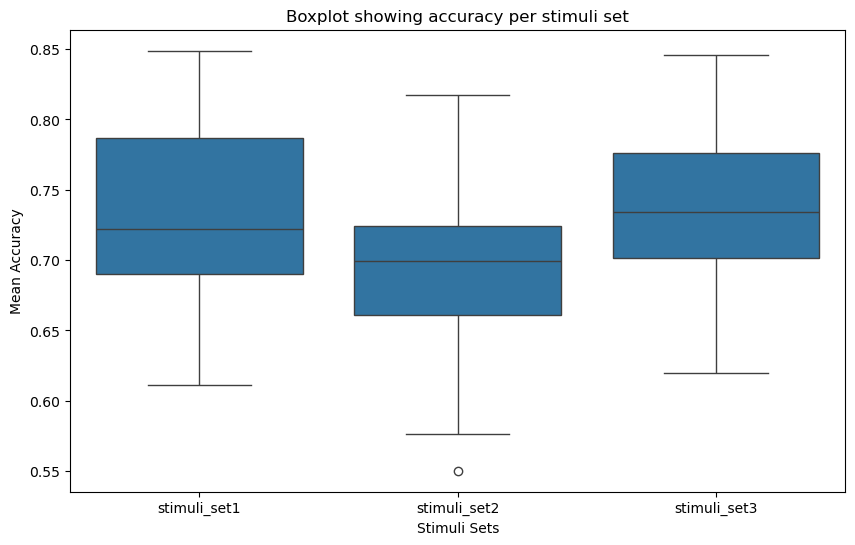

In [20]:
# Pingouin ANOVA
anova_result_acc_stimset = pg.anova(data=df, dv='acc_trial_concrete_cued', between='stimuli_set')
print('Pingouin Anova', anova_result_acc_stimset)

# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
if anova_result_acc_stimset['p-unc'].values[0] < alpha:
    print("The one-way ANOVA indicates a significant difference among the three stimuli sets.")
    tukey_stimset = pg.pairwise_tukey(dv='acc_trial_concrete_cued', between='stimuli_set', data=df)
    print(tukey_stimset)
else:
    print("The one-way ANOVA does not indicate a significant difference among the three stimuli sets.")


# Create an empty list to store grouped data for each participant
grouped_data_list = []

# Iterate through each participant in good_partis
for i in good_partis:
    # Group the data for the current participant
    data = df[df['subID'] == i].groupby(['stimuli_set'])['acc_trial_concrete_cued'].mean()
    
    # Append the grouped data to the list
    grouped_data_list.append(data)

# Concatenate the list of DataFrames into a single DataFrame
final_grouped_data = pd.concat(grouped_data_list)

# Reset the index to make 'subID' a regular column
final_grouped_data = final_grouped_data.reset_index()

# Plot boxplots for each participant
plt.figure(figsize=(10, 6))
sns.boxplot(x='stimuli_set', y='acc_trial_concrete_cued', data=final_grouped_data)
plt.title('Boxplot showing accuracy per stimuli set')
plt.xlabel('Stimuli Sets')
plt.ylabel('Mean Accuracy')
plt.show()

# Thus, we would conclude that there is a statistically significant difference between the means of sets 1 and 2 and sets 2 and 3, 
# but not a statistically significant difference between the means of sets 1 and 3. 

In [21]:
tukey_stimset

,A,B,mean(A),mean(B),diff,se,T,p-tukey,hedges
0,stimuli_set1,stimuli_set2,0.731019,0.690228,0.040790,0.007149,5.706032,3.506350e-08,0.087916
1,stimuli_set1,stimuli_set3,0.731019,0.727965,0.003054,0.007289,0.418930,9.078071e-01,0.006714
2,stimuli_set2,stimuli_set3,0.690228,0.727965,-0.037737,0.007409,-5.093103,1.062079e-06,-0.080925


## Mean accuracy by condition, oneway ANOVA

In [22]:

# does all three conditions in one and groups them by 'items_presented' which is the condition (can add .values at the end if I want only the answer values)
mean_cond = df.groupby('items_presented')['acc_trial_concrete_cued'].mean()
print("Mean accuracy per condition:", mean_cond)
mean_acc = df['acc_trial_concrete_cued'].mean()
print(mean_acc)

condition_means = mean_cond.tolist()
# why do I have the following line?
condition_labels = ['1', '2', '3']
# these turn out to be exactly the same size, I am a little suspicious that I indeed have exactly the same number of accuracy lines for every condition
# can remove this later, but might be interesting to check the number of samples per condition after I decide which participants to exclude
# len_sample_con1 = len(df[df['items_presented'] == 1])
# print('samples con1:', len_sample_con1)
# len_sample_con2 = len(df[df['items_presented'] == 2])
# print('samples con1:', len_sample_con2)
# len_sample_con3 = len(df[df['items_presented'] == 3])
# print('samples con1:', len_sample_con3)

# Pingouin ANOVA
anova_result_acc_items = pg.anova(data=df, dv='acc_trial_concrete_cued', between='items_presented')
print('Pingouin Anova', anova_result_acc_items)

# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
if anova_result_acc_items['p-unc'].values[0] < alpha:
    print("The one-way ANOVA indicates a significant difference among the three conditions.")
    tukey = pg.pairwise_tukey(dv='acc_trial_concrete_cued', between='items_presented', data=df)
    print(tukey)
else:
    print("The one-way ANOVA does not indicate a significant difference among the three conditions.")


Mean accuracy per condition: items_presented
1    0.798363
2    0.694568
3    0.656498
Name: acc_trial_concrete_cued, dtype: float64
0.7164765211640212
Pingouin Anova             Source  ddof1  ddof2           F         p-unc       np2
0  items_presented      2  24189  207.124681  6.433665e-90  0.016837
The one-way ANOVA indicates a significant difference among the three conditions.
   A  B   mean(A)   mean(B)      diff        se          T       p-tukey  \
0  1  2  0.798363  0.694568  0.103795  0.007215  14.385507  0.000000e+00   
1  1  3  0.798363  0.656498  0.141865  0.007215  19.661912  0.000000e+00   
2  2  3  0.694568  0.656498  0.038070  0.007215   5.276405  3.979354e-07   

     hedges  
0  0.233107  
1  0.313940  
2  0.079851  


## Accuraccy over time 

block_number
1     0.657407
2     0.668651
3     0.698413
4     0.695767
5     0.716270
6     0.703704
7     0.722222
8     0.750661
9     0.709656
10    0.744048
11    0.730820
12    0.732804
13    0.734788
14    0.720899
15    0.742725
16    0.734788
Name: acc_trial_concrete_cued, dtype: float64


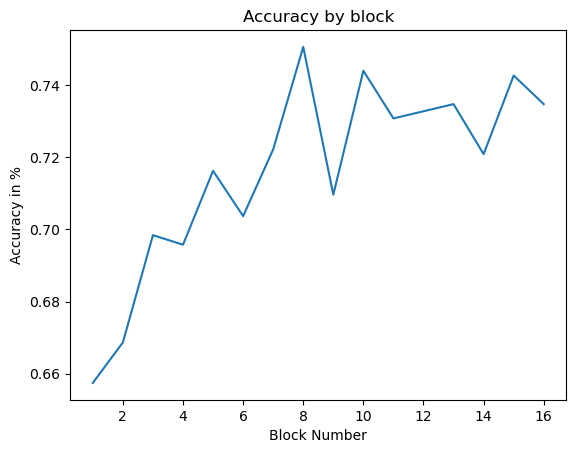

In [23]:
# ave_plot = matplotlib.pyplot.plot(ave_inflammation) -> general x/y plot
mean_block_allp = df.groupby('block_number')['acc_trial_concrete_cued'].mean()
print(mean_block_allp)
#df_sorted = df.sort_values(by='trial')
#print(df_sorted)
acc_by_block = plt.plot(mean_block_allp)
plt.xlabel('Block Number')  # Set the label for the x-axis
plt.ylabel('Accuracy in %')  # Set the label for the y-axis
plt.title('Accuracy by block')  # Set the title for the plot
plt.show()  # Display the plot

block_number
1     0.657407
2     0.668651
3     0.698413
4     0.695767
5     0.716270
6     0.703704
7     0.722222
8     0.750661
9     0.709656
10    0.744048
11    0.730820
12    0.732804
13    0.734788
14    0.720899
15    0.742725
16    0.734788
Name: acc_trial_concrete_cued, dtype: float64


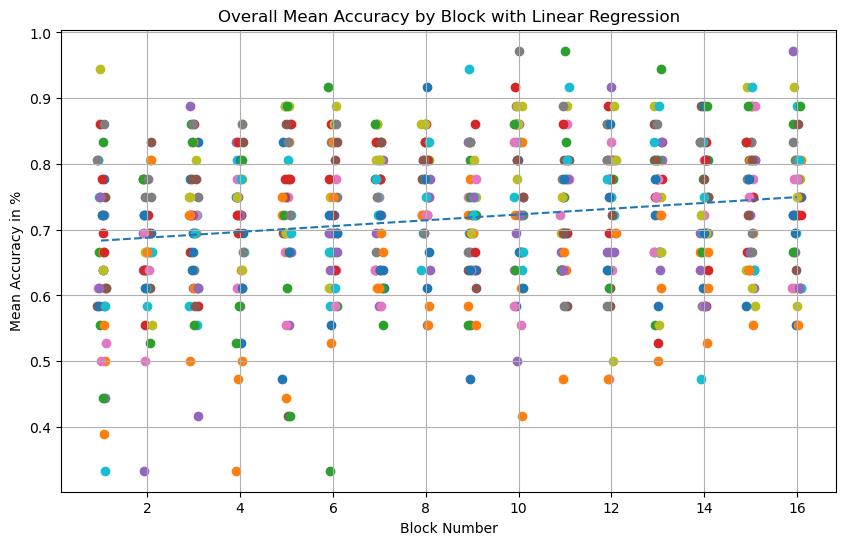

In [24]:
# Calculate the mean accuracy by block across all participants
mean_block_allp = df.groupby('block_number')['acc_trial_concrete_cued'].mean()
print(mean_block_allp)

# Access accuracy data by block for each participant
accuracy_data_by_participant = {}

for participant_id in df['subID'].unique():
    participant_data = df[df['subID'] == participant_id]
    mean_accuracy_by_block = participant_data.groupby('block_number')['acc_trial_concrete_cued'].mean()
    accuracy_data_by_participant[participant_id] = mean_accuracy_by_block

# Create a scatterplot for each participant
plt.figure(figsize=(10, 6))  # Adjust the figure size as needed

jitter = 0.1 


for participant_id, accuracy_series in accuracy_data_by_participant.items():
    
    # Add jitter to the x-axis values
    x_values = accuracy_series.index + np.random.uniform(-jitter, jitter, len(accuracy_series))

    plt.scatter(x_values, accuracy_series, label=f'Participant {participant_id}', marker='o')
    
    # # Perform linear regression for each participant
    # slope, intercept, r_value, p_value, std_err = stats.linregress(accuracy_series.index, accuracy_series)
    # plt.plot(x_values, intercept + slope * x_values, label=f'LinReg (p={p_value:.4f})', linestyle='--')


plt.xlabel('Block Number')
plt.ylabel('Accuracy in %')
plt.title('Accuracy by Block for Each Participant')

plt.grid(True)


# Perform a linear regression on the mean accuracy data
slope, intercept, r_value, p_value, std_err = stats.linregress(mean_block_allp.index, mean_block_allp)
# Plot the linear regression line
plt.plot(mean_block_allp.index, intercept + slope * mean_block_allp.index, label=f'LinReg (p={p_value:.4f})', linestyle='--')

plt.xlabel('Block Number')
plt.ylabel('Mean Accuracy in %')
plt.title('Overall Mean Accuracy by Block with Linear Regression')

plt.grid(True)
plt.show()


plt.show()

block_number
1     0.657407
2     0.668651
3     0.698413
4     0.695767
5     0.716270
6     0.703704
7     0.722222
8     0.750661
9     0.709656
10    0.744048
11    0.730820
12    0.732804
13    0.734788
14    0.720899
15    0.742725
16    0.734788
Name: acc_trial_concrete_cued, dtype: float64
P-value: 0.000260934071776305


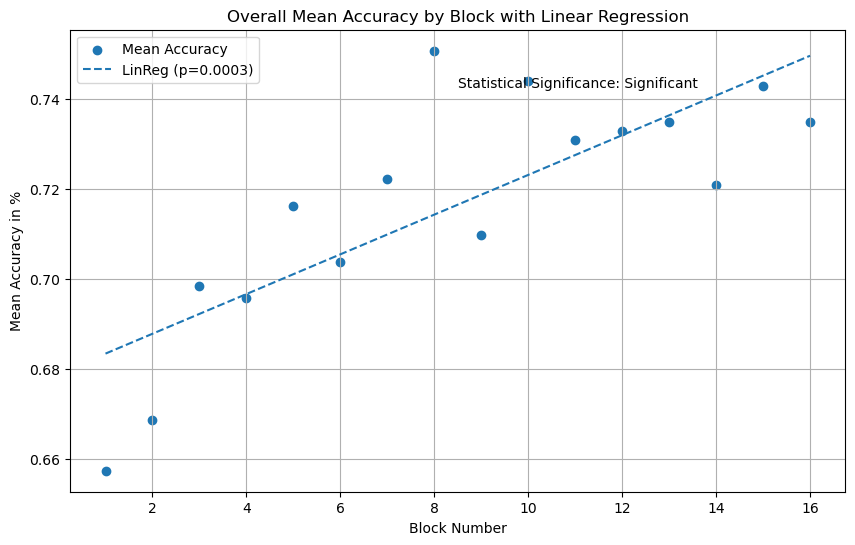

In [25]:
# Calculate the mean accuracy by block across all participants
mean_block_allp = df.groupby('block_number')['acc_trial_concrete_cued'].mean()
print(mean_block_allp)
# Perform a linear regression on the mean accuracy data
slope, intercept, r_value, p_value, std_err = stats.linregress(mean_block_allp.index, mean_block_allp)

# Create a scatterplot for the overall mean accuracy
plt.figure(figsize=(10, 6))  # Adjust the figure size as needed

plt.scatter(mean_block_allp.index, mean_block_allp, label='Mean Accuracy', marker='o')

# Plot the linear regression line
plt.plot(mean_block_allp.index, intercept + slope * mean_block_allp.index, label=f'LinReg (p={p_value:.4f})', linestyle='--')


print('P-value:', p_value)
# Add statistical significance annotation
if p_value < 0.05:
    significance = 'Significant'
else:
    significance = 'Not Significant'

plt.text(0.5, 0.9, f'Statistical Significance: {significance}', transform=plt.gca().transAxes, fontsize=10, verticalalignment='top')


plt.xlabel('Block Number')
plt.ylabel('Mean Accuracy in %')
plt.title('Overall Mean Accuracy by Block with Linear Regression')
plt.legend()
plt.grid(True)
plt.show()

## Accuracy depending on mnemonic distance? (position 1, 2 or 3)

Can only compare those in 
- position 1 (load 1)
- position 1 (load 2)
- position 1 (load 3)
- position 2 (load 2)
- position 2 (load 3)
- position 3 (load 3)

In [26]:
# # One way Anova
# # might want to group the data into either all data position 1, or group them seperately for the conditions as well
# # accuracy for position of item within the load conditions (mnemonic distance?, in position two and three they should be remembered better)

# # Make a dictionary 
# # in seconds 
# mne_dist_dict = {
#     "position1/load1": 3.5,
#     "position1/load2": 5.5,
#     "position1/load3": 6.5,
#     "position2/load2": 4.5,
#     "position2/load3": 5.5,
#     "position3/load3": 4.5
# }



# ## could actually calculate or at least list the actual distances between when the objects where shown and their test

# # just use the object at test in relation to its position during the learning period to check which position/laod
# # maybe rather use the object ID
# if df['stimuli_set'] == stimuli_set1:
#     if df['items_presented']==1
#         if object_test_id_cued == object_1_id

#         # need for elseif?
#         # what data to I ultimately want -> accuracy
#         accuracy_pos1_load1 = 

#      if df['items_presented']==2
#         if object_test_id_cued == object_1_id

#         # need for elseif?
#         # what data to I ultimately want -> accuracy
#         accuracy_pos1_load2 =

#      if df['items_presented']== 2
#         if object_test_id_cued == object_2_id

#         # need for elseif?
#         # what data to I ultimately want -> accuracy
#         accuracy_pos2_load2 = 

#      if df['items_presented']== 3
#         if object_test_id_cued == object_1_id

#         # need for elseif?
#         # what data to I ultimately want -> accuracy
#         accuracy_pos1_load3 = 

#      if df['items_presented']== 3
#         if object_test_id_cued == object_2_id

#         # need for elseif?
#         # what data to I ultimately want -> accuracy
#         accuracy_pos2_load3 = 

#      if df['items_presented']== 3
#         if object_test_id_cued == object_3_id

#         # need for elseif?
#         # what data to I ultimately want -> accuracy
#         accuracy_pos3_load3 = 

# # could this be done without the if items_presented? Does it matter if I sort by load first? Yes because the line afterwards
# # would otherwise be identical for some positions 

# # Distance Error
# # The distances between stim1 and its test are:
# ## meaning only in position 1 the distance in load 1 would be 0.5s for object timeout + 0.5s for fixation cross? (need to check in the lab)
# ## 3.5 ???


# # - Load1: 4 seconds (**error**!, it should be 1 + 3.5 seconds). ---> ## how did it end up being 4?
# # - Load2: 5.5 seconds (2+ 3.5 seconds).
# # - Load3: 6.5 seconds (3 + 3.5 seconds).


# Circular Stuff

## Oblique Effect

## Oblique Effect T-Test

mean per category:  Cardinal_Category
Cardinal    0.735101
Oblique     0.698051
Name: acc_trial_concrete_cued, dtype: float64
   Cardinal_Category  acc_trial_concrete_cued
0           Cardinal                 0.836066
1            Oblique                 0.745387
2           Cardinal                 0.725000
3            Oblique                 0.638514
4           Cardinal                 0.842657
..               ...                      ...
79           Oblique                 0.749164
80          Cardinal                 0.697917
81           Oblique                 0.729167
82          Cardinal                 0.537906
83           Oblique                 0.561873

[84 rows x 2 columns]


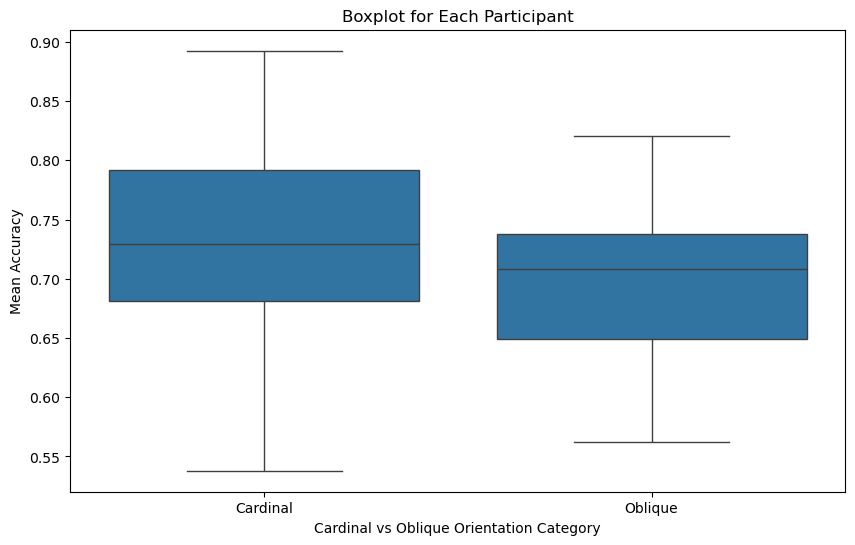

               T  dof alternative     p-val        CI95%  cohen-d   BF10  \
T-test  2.218838   82   two-sided  0.029261  [0.0, 0.07]  0.48419  1.892   

           power  
T-test  0.592072  
T-statistic: [2.21883787]
P-value: [0.02926109]
The t-test indicates a significant difference between accuracy in oblique vs. cardinal orientations


In [27]:

# orientations closest to the cardinal axes
orientation_subset_cardinal = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]


# Create a new column to indicate the categories
df['Cardinal_Category'] = df['object_cued_rot'].apply(lambda x: 'Cardinal' if x in orientation_subset_cardinal else 'Oblique')

# Calculate mean accuracy for each category
mean_per_category = df.groupby('Cardinal_Category')['acc_trial_concrete_cued'].mean()
print("mean per category: ", mean_per_category)

# Create an empty list to store grouped data for each participant
grouped_data_list = []

# Iterate through each participant in good_partis
for i in good_partis:
    # Group the data for the current participant
    data = df[df['subID'] == i].groupby(['Cardinal_Category'])['acc_trial_concrete_cued'].mean()
    
    # Append the grouped data to the list
    grouped_data_list.append(data)

# Concatenate the list of DataFrames into a single DataFrame
final_grouped_data_obli = pd.concat(grouped_data_list)

# Reset the index to make 'subID' a regular column
final_grouped_data_obli = final_grouped_data_obli.reset_index()
print(final_grouped_data_obli)

# Plot boxplots for each participant
plt.figure(figsize=(10, 6))
sns.boxplot(x='Cardinal_Category', y='acc_trial_concrete_cued', data=final_grouped_data_obli)
plt.title('Boxplot for Each Participant')
plt.xlabel('Cardinal vs Oblique Orientation Category')
plt.ylabel('Mean Accuracy')
plt.show()

# Statistics
# these have different results than the statistics below that I originally computed
# the final_grouped_data is data that has a mean per orientation for every participant
# below I used the mean per orientation across all participants (grouped_cardinal has 16 entries, final_grouped data (used here) has 640 entries (40 participants x 16 orientations))


oblique_data = final_grouped_data_obli[final_grouped_data_obli['Cardinal_Category'] == 'Oblique']['acc_trial_concrete_cued']
cardinal_data = final_grouped_data_obli[final_grouped_data_obli['Cardinal_Category'] == 'Cardinal']['acc_trial_concrete_cued']

# t_statistic, p_value = stats.ttest_ind(cardinal_data, oblique_data)
result_ttest_obli = pg.ttest(cardinal_data, oblique_data)
print(result_ttest_obli)

# Access specific properties
p_value = result_ttest_obli['p-val'].values
t_statistic = result_ttest_obli['T'].values

# Define the significance level (alpha)
alpha = 0.05

print("T-statistic:", t_statistic)
print("P-value:", p_value)


if p_value < alpha:
    print("The t-test indicates a significant difference between accuracy in oblique vs. cardinal orientations")
else:
    print("The t-test does not indicate a significant difference between accuracy in oblique vs. cardinal orientations")

# could add significance brackets. Easiest way would be to use statannotations but that lead to errors last time..




In [28]:
result_ttest_obli

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,2.218838,82,two-sided,0.029261,"[0.0, 0.07]",0.48419,1.892,0.592072


   Cardinal_Category      mean       std   subID  items_presented
0           Cardinal  0.895833  0.307080  Z16JQR                1
1            Oblique  0.781250  0.415569  Z16JQR                1
0           Cardinal  0.870370  0.337461  Z16JQR                2
1            Oblique  0.702381  0.459957  Z16JQR                2
0           Cardinal  0.742574  0.439397  Z16JQR                3
..               ...       ...       ...     ...              ...
1            Oblique  0.645833  0.502188  30K8XE                1
0           Cardinal  0.521277  0.523198  30K8XE                2
1            Oblique  0.581633  0.516201  30K8XE                2
0           Cardinal  0.505747  0.502865  30K8XE                3
1            Oblique  0.466667  0.501280  30K8XE                3

[252 rows x 5 columns]
                                Source        SS  ddof1  ddof2        MS  \
0                    Cardinal_Category  0.081798      1     41  0.081798   
1                      items_pre

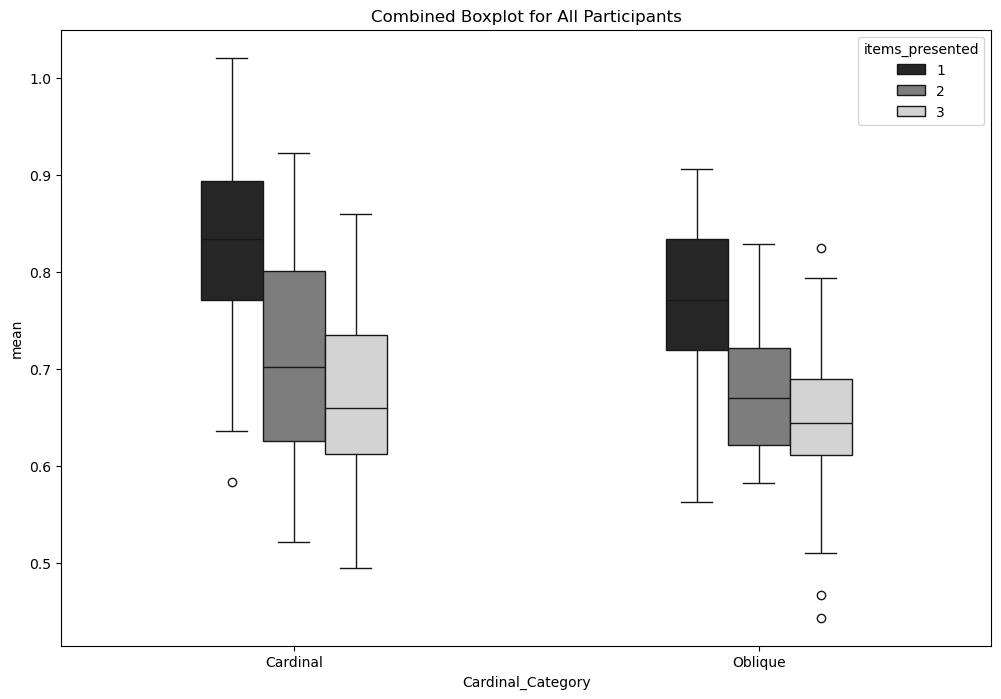

In [29]:
# comparing load conditions:

# participant_data_obli_con = []
# obli_con_list = []

all_p_obli_con = pd.DataFrame()

# Iterate through each participant in good_partis
for i in good_partis:
    # Group the data for the current participant
    # data = df[df['subID'] == i].groupby(['Cardinal_Category'])['acc_trial_concrete_cued'].mean()
    participant_data_obli_con = df.loc[df['subID'] == i, ['Cardinal_Category', 'acc_trial_concrete_cued', 'object_cued_rot', 'items_presented']]
    #participant_data1 = df.loc[(df['subID'] == i) & (df['items_presented'] == 1), 'acc_trial_concrete_cued']
        # condition 1
    #bp_con1 = participant_data.loc[participant_data['items_presented'] == 1].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()
    acc_obli_con1 = participant_data_obli_con.loc[participant_data_obli_con['items_presented'] == 1].groupby('Cardinal_Category')['acc_trial_concrete_cued'].agg(['mean', 'std']).reset_index()
    acc_obli_con1['subID'] = i
    acc_obli_con1['items_presented'] = 1
    # condition 2
    #bp_con2 = participant_data.loc[participant_data['items_presented'] == 2].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()
    acc_obli_con2 = participant_data_obli_con.loc[participant_data_obli_con['items_presented'] == 2].groupby('Cardinal_Category')['acc_trial_concrete_cued'].agg(['mean', 'std']).reset_index()
    acc_obli_con2['subID'] = i
    acc_obli_con2['items_presented'] = 2
    #bp_con3 = participant_data.loc[participant_data['items_presented'] == 3].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()
    acc_obli_con3 = participant_data_obli_con.loc[participant_data_obli_con['items_presented'] == 3].groupby('Cardinal_Category')['acc_trial_concrete_cued'].agg(['mean', 'std']).reset_index()
    acc_obli_con3['subID'] = i
    acc_obli_con3['items_presented'] = 3
    # Append the grouped data to the list
    #obli_con_list.append(participant_data_obli_con)

    
    all_p_obli_con = pd.concat([all_p_obli_con, acc_obli_con1])
    all_p_obli_con = pd.concat([all_p_obli_con, acc_obli_con2])
    all_p_obli_con = pd.concat([all_p_obli_con, acc_obli_con3])
print(all_p_obli_con)
    
# Box plot for all conditions for all participants
plt.figure(figsize=(12, 8))

# Subplot for all conditions
# sharey=True
plt.subplot() #221
sns.boxplot(x='Cardinal_Category', y='mean', hue='items_presented', data=all_p_obli_con, width=0.4, palette='dark:lightgray')
plt.title('Combined Boxplot for All Participants')

# Anova

# should I do a repeated measures anova here?
# run it on the df or the all_p_obli_c

# Perform ANOVA
alpha = 0.05
result_anova_obli_con = pg.rm_anova(data=all_p_obli_con, dv='mean', within=['Cardinal_Category', 'items_presented'], subject='subID')

# the following two work but probably for all the wrong reasons
# should be a repeated measures anova, not pg.anova
# result_anova = pg.anova(data=all_p_obli_con, dv='mean', between=['Cardinal_Category', 'items_presented'])
# result_anova = pg.anova(data=final_grouped_data, dv='acc_trial_concrete_cued', between=['Cardinal_Category', 'items_presented'])

# Print ANOVA results
print(result_anova_obli_con)


In [30]:
# result_anova_obli_con = pg.rm_anova(data=all_p_obli_con, dv='mean', within=['Cardinal_Category', 'items_presented'], subject='subID')

result_anova_single = pg.anova(data=all_p_obli_con, dv='mean', between=['Cardinal_Category'])
result_anova_single

,Source,ddof1,ddof2,F,p-unc,np2
0,Cardinal_Category,1,250,7.362204,0.007124,0.028606


In [31]:
result_anova_obli_con

,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,Cardinal_Category,0.081798,1,41,0.081798,13.886209,5.866438e-04,5.866438e-04,0.042032,1.000000
1,items_presented,0.905634,2,82,0.452817,142.097965,2.260028e-27,1.379425e-23,0.326953,0.847948
2,Cardinal_Category * items_presented,0.007711,2,82,0.003855,1.656111,1.971998e-01,2.017823e-01,0.004119,0.840305


In [32]:
# Perform repeated-measures ANOVA
result_anova = pg.rm_anova(data=df, dv='acc_trial_concrete_cued', within='items_presented', subject='subID')

# Print ANOVA results
print(result_anova)


            Source  ddof1  ddof2           F         p-unc      ng2       eps
0  items_presented      2     82  142.036057  2.291582e-27  0.38711  0.860716


### two categories (oblique vs cardinal)

acc_df: object_cued_rot  items_presented
11.25            1                  0.851190
                 2                  0.718690
                 3                  0.705773
33.75            1                  0.791667
                 2                  0.731225
                 3                  0.701923
56.25            1                  0.785714
                 2                  0.642447
                 3                  0.593878
78.75            1                  0.797619
                 2                  0.731610
                 3                  0.637295
101.25           1                  0.815476
                 2                  0.713978
                 3                  0.629482
123.75           1                  0.734127
                 2                  0.666008
                 3                  0.629259
146.25           1                  0.763889
                 2                  0.701375
                 3                  0.633270
168.75        

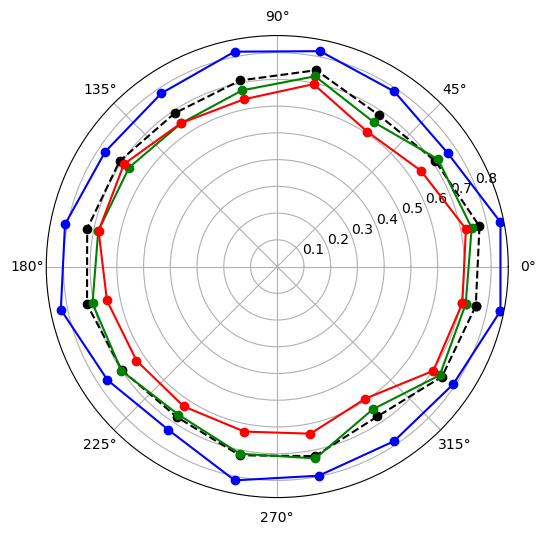

In [33]:
## Plotting the Oblique effect on a polar plot

spacing = np.arange(11.25, 360, 22.5)
spacing_rad = np.radians(spacing)

## change the above line to make it so that positive is going anticlockwise. Apparently theta is always going anticlockwise

# making it a full circle
spacing_circ = np.append(spacing_rad, spacing_rad[0])

acc_per_ori = df.groupby('object_cued_rot')['acc_trial_concrete_cued'].mean().values

acc_df = df.groupby(by=['object_cued_rot', 'items_presented'])['acc_trial_concrete_cued'].mean()
#print(mbp_df)
#-> this output looks right but looking at the variable mbp_df in the data viewer looks weird
# -> this returns a dataframe called mbp_df that is the same size as df but is sorted by object_cued_rot and within each object_cued_rot it is then sorted by items_presented

# seperate by con
oriacc1 = acc_df.loc[acc_df.index.get_level_values('items_presented') == 1].to_numpy()
oriacc2 = acc_df.loc[acc_df.index.get_level_values('items_presented') == 2].to_numpy()
oriacc3 = acc_df.loc[acc_df.index.get_level_values('items_presented') == 3].to_numpy()

print("acc_df:", acc_df)
print("oriacc1:", oriacc1)
print("oriacc2:", oriacc2)
print("oriacc3:", oriacc3)

# Create the polar plot
fig = plt.figure(figsize=(10,6))
# maybe change the following line to plt.axes(projection='polar')
ax = fig.add_subplot(111, projection='polar')

#Repeating the last data point to make it a full circle
# mbp_rad = np.append(mbp_rad, mbp_rad[0])
# mbp1_rad = np.append(mbp1_rad, mbp1_rad[0])
# mbp2_rad = np.append(mbp2_rad, mbp2_rad[0])
# mbp3_rad = np.append(mbp3_rad, mbp3_rad[0])

acc_per_ori_circ = np.append(acc_per_ori, acc_per_ori[0])
oriacc1_circ = np.append(oriacc1, oriacc1[0])
oriacc2_circ = np.append(oriacc2, oriacc2[0])
oriacc3_circ = np.append(oriacc3, oriacc3[0])

# Plot the data for the general mbp
ax.plot(-spacing_circ, acc_per_ori_circ, 'ko--')

unbiased_assumption = np.full(17, 0.5)

# # Plot the data for the three conditions individually
# at the moment using -spacing_rad to make the data go in the correct (anticlockwise direction)
# ax.plot(-spacing_circ, unbiased_assumption, color='tab:pink', linestyle='dashed')
ax.plot(-spacing_circ, oriacc1_circ, 'bo-')
ax.plot(-spacing_circ, oriacc2_circ, 'go-')
ax.plot(-spacing_circ, oriacc3_circ, 'ro-')


# Set plot attributes (-> labels and shit)
plt.legend
# Show the plot
plt.show()


### 4 categories (A,B,C,D) referring to the four equal distances from cardinal axes

                     mean       std   subID
Orientation_Bin                            
Ori Bin A        0.852564  0.355682  Z16JQR
Ori Bin B        0.716535  0.452465  Z16JQR
Ori Bin C        0.770833  0.421764  Z16JQR
Ori Bin D        0.818792  0.386490  Z16JQR
                     mean       std
Orientation_Bin                    
Ori Bin A        0.895833  0.308709
Ori Bin B        0.729167  0.449093
Ori Bin C        0.833333  0.376622
Ori Bin D        0.895833  0.308709
                     mean       std   subID
Orientation_Bin                            
Ori Bin A        0.852564  0.355682  Z16JQR
Ori Bin B        0.716535  0.452465  Z16JQR
Ori Bin C        0.770833  0.421764  Z16JQR
Ori Bin D        0.818792  0.386490  Z16JQR
Ori Bin A        0.767606  0.456093  C9A31N
Ori Bin B        0.605442  0.490426  C9A31N
Ori Bin C        0.671141  0.485505  C9A31N
Ori Bin D        0.681159  0.467725  C9A31N
                     mean       std
Orientation_Bin                    
Ori Bin 

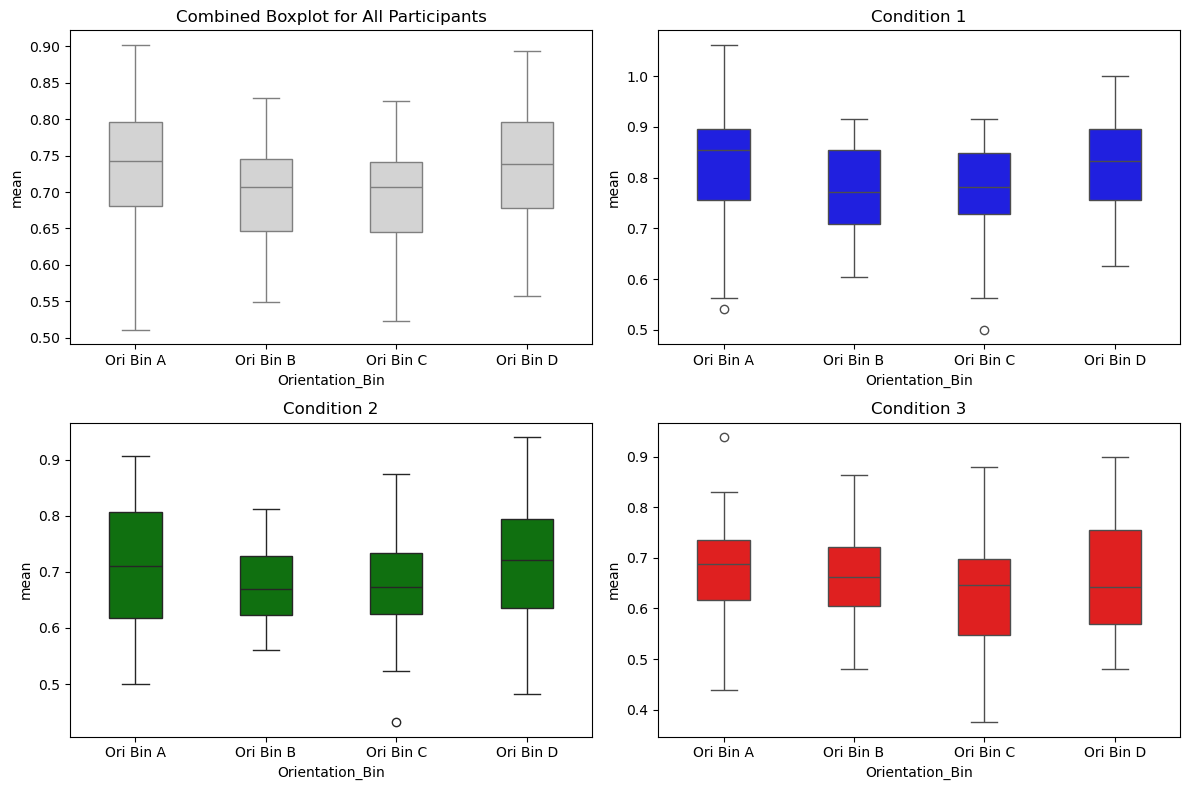

In [34]:
all_participants_data = pd.DataFrame()
acc_oribin_con1_all = pd.DataFrame()
acc_oribin_con2_all = pd.DataFrame()
acc_oribin_con3_all = pd.DataFrame()

for i in good_partis:

    # all conditions
    participant_data = df.loc[df['subID'] == i, ['Orientation_Bin', 'acc_trial_concrete_cued', 'object_cued_rot', 'items_presented']]
    # print(participant_data)
    # I need to then mean the data per participant (within the loop it is single participant data) by ori - so I have a mean per ori per pp
    
    # grouped_data = participant_data.groupby(['object_cued_rot', 'items_presented'])['button_press_clockwise'].mean()
    

    # can I rename the column names of the following dfs to not have the column names be called mean and std?
    # all conditions
    acc_oribin_allcon = participant_data.groupby('Orientation_Bin')['acc_trial_concrete_cued'].agg(['mean', 'std'])

    # removing the reset_index changes not the all_con but the following plots??
    # all_con_data = participant_data.groupby('Orientation_Bin')['button_press_clockwise'].agg(['mean', 'std'])
    
    # condition 1
    #bp_con1 = participant_data.loc[participant_data['items_presented'] == 1].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()
    acc_oribin_con1 = participant_data.loc[participant_data['items_presented'] == 1].groupby('Orientation_Bin')['acc_trial_concrete_cued'].agg(['mean', 'std'])
    
    # condition 2
    #bp_con2 = participant_data.loc[participant_data['items_presented'] == 2].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()
    acc_oribin_con2 = participant_data.loc[participant_data['items_presented'] == 2].groupby('Orientation_Bin')['acc_trial_concrete_cued'].agg(['mean', 'std'])

    #bp_con3 = participant_data.loc[participant_data['items_presented'] == 3].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()
    acc_oribin_con3 = participant_data.loc[participant_data['items_presented'] == 3].groupby('Orientation_Bin')['acc_trial_concrete_cued'].agg(['mean', 'std'])

    # Append the data for the current participant to the cumulative DataFrame

    # unsure if the following variable saves the data correctly, not enough inputs?
    # should be 16 values per participant and there are 40 participants
    # or are they meaned for each ori bin before and therefore there are only 4 values per participant? - this seems correct, there are 160 columns (4*40)
    # however this is only for all conditions

    # Add a column for participant ID
    acc_oribin_allcon['subID'] = i
    all_participants_data = pd.concat([all_participants_data, acc_oribin_allcon])
    print(all_participants_data)
    # print(acc_oribin_allcon)

    acc_oribin_con1_all = pd.concat([acc_oribin_con1_all, acc_oribin_con1])
    print(acc_oribin_con1_all)
    acc_oribin_con2_all = pd.concat([acc_oribin_con2_all, acc_oribin_con2])
    acc_oribin_con3_all = pd.concat([acc_oribin_con3_all, acc_oribin_con3])
    # # Visualize the data with box plots for each participant
    # plt.figure(figsize=(12, 8))
    
    # # Box plot for conditions 1, 2, and 3
    # sns.boxplot(x='Orientation_Bin', y='mean', data=bp_con1, width=0.3, color='lightblue')
    # sns.boxplot(x='Orientation_Bin', y='mean', data=bp_con2, width=0.3, color='lightgreen')
    # sns.boxplot(x='Orientation_Bin', y='mean', data=bp_con3, width=0.3, color='lightcoral')

    # plt.title(f'Boxplot for Participant {i}')
    # plt.legend()

#print(all_participants_data)
# Visualize the data with a combined box plot for all participants


# # Box plot for all conditions for all participants
# plt.figure(figsize=(12, 8))
# sns.boxplot(x='Orientation_Bin', y='mean', data=all_participants_data, width=0.4, color='lightgray')
# plt.figure(figsize=(12, 8))
# sns.boxplot(x='Orientation_Bin', y='mean', data=acc_oribin_con1, width=0.4, color='blue')
# plt.figure(figsize=(12, 8))
# sns.boxplot(x='Orientation_Bin', y='mean', data=acc_oribin_con2, width=0.4, color='green')
# plt.figure(figsize=(12, 8))
# sns.boxplot(x='Orientation_Bin', y='mean', data=acc_oribin_con3, width=0.4, color='red')
# plt.title('Combined Boxplot for All Participants')
# plt.legend()
# plt.show()

# Box plot for all conditions for all participants
plt.figure(figsize=(12, 8))

# Subplot for all conditions
plt.subplot(221)
sns.boxplot(x='Orientation_Bin', y='mean', data=all_participants_data, width=0.4, color='lightgray')
plt.title('Combined Boxplot for All Participants')

# Subplot for condition 1
plt.subplot(222)
sns.boxplot(x='Orientation_Bin', y='mean', data=acc_oribin_con1_all, width=0.4, color='blue')
plt.title('Condition 1')

# Subplot for condition 2
plt.subplot(223)
sns.boxplot(x='Orientation_Bin', y='mean', data=acc_oribin_con2_all, width=0.4, color='green')
plt.title('Condition 2')

# Subplot for condition 3
plt.subplot(224)
sns.boxplot(x='Orientation_Bin', y='mean', data=acc_oribin_con3_all, width=0.4, color='red')
plt.title('Condition 3')

plt.tight_layout()
plt.show()

## Cardinal Repulsion

                     mean       std   subID
Orientation_Bin                            
Ori Bin A        0.544872  0.499586  Z16JQR
Ori Bin B        0.637795  0.482541  Z16JQR
Ori Bin C        0.465278  0.500534  Z16JQR
Ori Bin D        0.416107  0.494574  Z16JQR
Ori Bin A        0.520833  0.504852     NaN
Ori Bin B        0.625000  0.489246     NaN
Ori Bin C        0.437500  0.501328     NaN
Ori Bin D        0.520833  0.504852     NaN
                     mean       std   subID
Orientation_Bin                            
Ori Bin A        0.544872  0.499586  Z16JQR
Ori Bin B        0.637795  0.482541  Z16JQR
Ori Bin C        0.465278  0.500534  Z16JQR
Ori Bin D        0.416107  0.494574  Z16JQR
Ori Bin A        0.528169  0.500973  C9A31N
Ori Bin B        0.442177  0.498343  C9A31N
Ori Bin C        0.442953  0.498410  C9A31N
Ori Bin D        0.528986  0.500978  C9A31N
Ori Bin A        0.479167  0.504852     NaN
Ori Bin B        0.395833  0.494204     NaN
Ori Bin C        0.416667  0.498

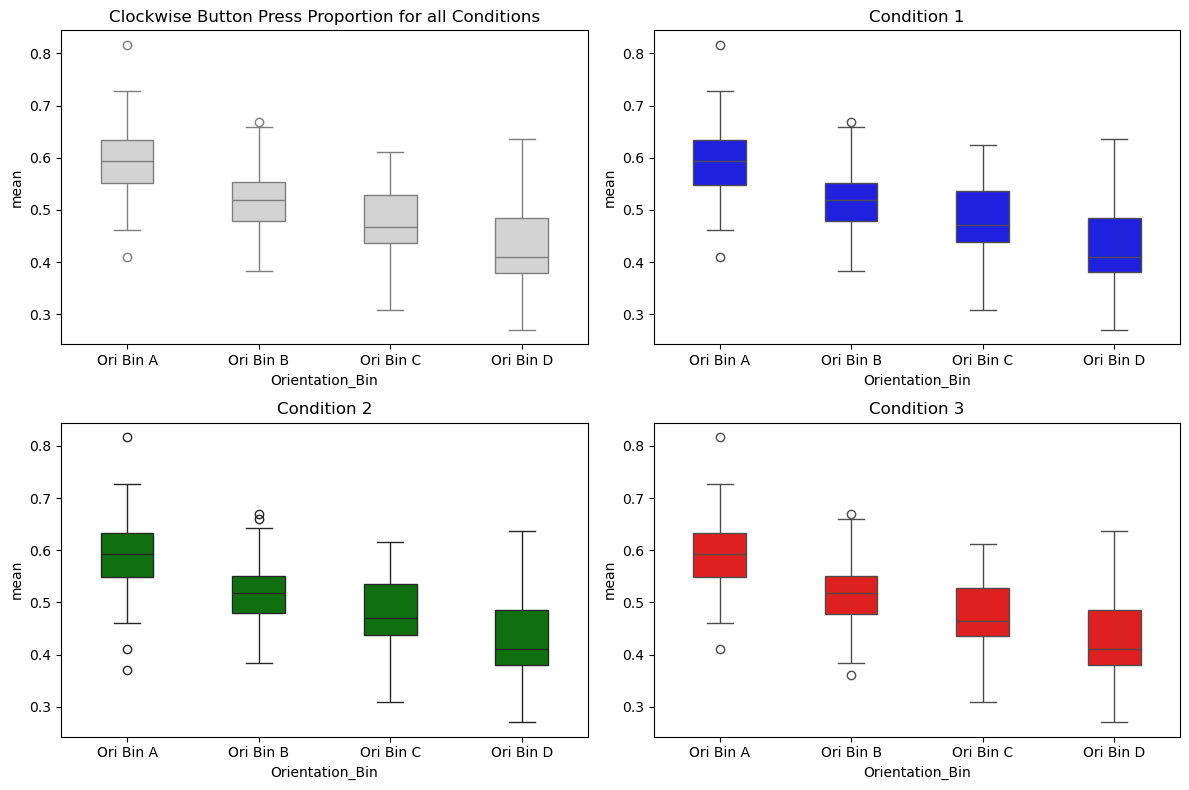

In [35]:
# Create an empty DataFrame to accumulate data for all participants
all_participants_data = pd.DataFrame()

for i in good_partis:

    # all conditions
    # changed this line with the help of ChatGPT, maybe not use groupby as done previously but rather like below but also df.loc
    # participant_data = df[df['subID'] == i].groupby(['Orientation_Bin'])['button_press_clockwise']
    # print(participant_data)
    participant_data = df.loc[df['subID'] == i, ['Orientation_Bin', 'button_press_clockwise', 'object_cued_rot', 'items_presented']]
    # print(participant_data)
    # I need to then mean the data per participant (within the loop it is single participant data) by ori - so I have a mean per ori per pp
    
    # grouped_data = participant_data.groupby(['object_cued_rot', 'items_presented'])['button_press_clockwise'].mean()
    

    # can I rename the column names of the following dfs to not have the column names be called mean and std?
    # all conditions
    all_con_data = participant_data.groupby('Orientation_Bin')['button_press_clockwise'].agg(['mean', 'std'])

    # removing the reset_index changes not the all_con but the following plots??
    # all_con_data = participant_data.groupby('Orientation_Bin')['button_press_clockwise'].agg(['mean', 'std'])

    # condition 1
    #bp_con1 = participant_data.loc[participant_data['items_presented'] == 1].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()
    bp_con1 = participant_data.loc[participant_data['items_presented'] == 1].groupby('Orientation_Bin')['button_press_clockwise'].agg(['mean', 'std'])
    
    # condition 2
    #bp_con2 = participant_data.loc[participant_data['items_presented'] == 2].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()
    bp_con2 = participant_data.loc[participant_data['items_presented'] == 2].groupby('Orientation_Bin')['button_press_clockwise'].agg(['mean', 'std'])

    #bp_con3 = participant_data.loc[participant_data['items_presented'] == 3].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()
    bp_con3 = participant_data.loc[participant_data['items_presented'] == 3].groupby('Orientation_Bin')['button_press_clockwise'].agg(['mean', 'std'])
    
    #print(bp_con3)

# Append the data for the current participant to the cumulative DataFrame

    # unsure if the following variable saves the data correctly, not enough inputs?
    # should be 16 values per participant and there are 40 participants
    # or are they meaned for each ori bin before and therefore there are only 4 values per participant? - this seems correct, there are 160 columns (4*40)
    # however this is only for all conditions

     # Add a column for participant ID
    all_con_data['subID'] = i
    all_participants_data = pd.concat([all_participants_data, all_con_data])
    # print(all_con_data)

    bp_con1_all = pd.concat([all_participants_data, bp_con1])
    print(bp_con1_all)
    bp_con2_all = pd.concat([all_participants_data, bp_con2])
    bp_con3_all = pd.concat([all_participants_data, bp_con3])
    # # Visualize the data with box plots for each participant
    # plt.figure(figsize=(12, 8))
    
    # # Box plot for conditions 1, 2, and 3
    # sns.boxplot(x='Orientation_Bin', y='mean', data=bp_con1, width=0.3, color='lightblue')
    # sns.boxplot(x='Orientation_Bin', y='mean', data=bp_con2, width=0.3, color='lightgreen')
    # sns.boxplot(x='Orientation_Bin', y='mean', data=bp_con3, width=0.3, color='lightcoral')

    # plt.title(f'Boxplot for Participant {i}')
    # plt.legend()

#print(all_participants_data)
# Visualize the data with a combined box plot for all participants


# # Box plot for all conditions for all participants
# plt.figure(figsize=(12, 8))
# sns.boxplot(x='Orientation_Bin', y='mean', data=all_participants_data, width=0.4, color='lightgray')
# plt.figure(figsize=(12, 8))
# sns.boxplot(x='Orientation_Bin', y='mean', data=bp_con1_all, width=0.4, color='blue')
# plt.figure(figsize=(12, 8))
# sns.boxplot(x='Orientation_Bin', y='mean', data=bp_con2_all, width=0.4, color='green')
# plt.figure(figsize=(12, 8))
# sns.boxplot(x='Orientation_Bin', y='mean', data=bp_con3_all, width=0.4, color='red')
# plt.title('Combined Boxplot for All Participants')
# plt.legend()
# plt.show()

# Box plot for all conditions for all participants
plt.figure(figsize=(12, 8))

# Subplot for all conditions
plt.subplot(221)
sns.boxplot(x='Orientation_Bin', y='mean', data=all_participants_data, width=0.4, color='lightgray')
plt.title('Clockwise Button Press Proportion for all Conditions')

# Subplot for condition 1
plt.subplot(222)
sns.boxplot(x='Orientation_Bin', y='mean', data=bp_con1_all, width=0.4, color='blue')
plt.title('Condition 1')

# Subplot for condition 2
plt.subplot(223)
sns.boxplot(x='Orientation_Bin', y='mean', data=bp_con2_all, width=0.4, color='green')
plt.title('Condition 2')

# Subplot for condition 3
plt.subplot(224)
sns.boxplot(x='Orientation_Bin', y='mean', data=bp_con3_all, width=0.4, color='red')
plt.title('Condition 3')

plt.tight_layout()
plt.show()

In [36]:
# this isnt too informative because the mean for all orientations is very close to 0.5 for all conditions

# mean clockwise proportion of all button presses
# mbp = mean button press 
mbp = df['button_press_clockwise'].mean()
print("the mean of all button presses is:", mbp)

# mean button press per condition

mbp_per_con = df.groupby('items_presented')['button_press_clockwise'].mean()
print("this is the mbp_per_con:", mbp_per_con)

# mean button press per rotation/ori
mbp_per_ori = df.groupby('object_cued_rot')['button_press_clockwise'].mean().values
print("button presses grouped by rotation:", mbp_per_ori)

the mean of all button presses is: 0.503968253968254
this is the mbp_per_con: items_presented
1    0.506324
2    0.506448
3    0.499132
Name: button_press_clockwise, dtype: float64
button presses grouped by rotation: [0.57948718 0.46143791 0.43177324 0.40267559 0.55404487 0.47514911
 0.43709468 0.38682322 0.61615487 0.57245431 0.52921865 0.49933599
 0.62897766 0.57306397 0.51411687 0.40576794]


### Cardinal Repulsion Bias Plot (?)
For the polar plot I can either: plt.axes(projection='polar'), plt.polar() or fig = plt.figure() + ax = fig.add_subplot(111, projection='polar')

I think I started the following bullet points when simultaneosly reading the Memoreye paper
Calculating whether
1) a repulsion bias occured (bias away from the cardinal axes)
2)

MBP: 0.503968253968254
MBP1: [0.55357143 0.48611111 0.43253968 0.38888889 0.56150794 0.43055556
 0.41269841 0.46031746 0.62103175 0.55753968 0.52777778 0.50396825
 0.63095238 0.56944444 0.52380952 0.44047619]
MBP2: [0.59152216 0.46640316 0.43594646 0.42743539 0.54623656 0.51185771
 0.45776031 0.36926148 0.60961538 0.57333333 0.4990099  0.50101833
 0.63817097 0.58401639 0.51287129 0.37575758]
MBP3: [0.59217877 0.43269231 0.42653061 0.39139344 0.55378486 0.48296593
 0.44045369 0.33333333 0.61814346 0.58648111 0.56031128 0.49315068
 0.61702128 0.56592292 0.50583658 0.4004065 ]


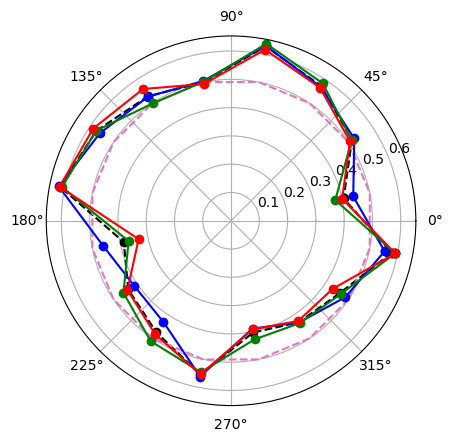

In [37]:
# Original Plot

# since I transformed the data to radians, the data is no longer between 0 and 1 but between 0.001 and 0.2 (I think). Therefore the tick labels on the plot are not reflecting the actual data. In the plot below (next code cell) I managred to transform the data back but the it looks like the 
# maximum value of 0.63 is never reached so something might be off. 
# Also the plot still looks like the opposite of what Juan was plotting. WHY???
# maybe I need to double check where the starting point of my data is. If the first point would be plotted one orientation too far into the clockwise direction it would look very different. I doubt this is what is going on though since the overall shape looks pretty good
# could I use degrees instead of radians?

# spacing is what is usually called theta in the polar plots. not sure if this is correct or just a butched way that works, 
# could also be coded using np.arange of divisions of pi, which is more common practice but harder to read
spacing = np.arange(11.25, 360, 22.5)
spacing_rad = np.radians(spacing)

## change the above line to make it so that positive is going anticlockwise. Apparently theta is always going anticlockwise

# making it a full circle
spacing_circ = np.append(spacing_rad, spacing_rad[0])

mbp_df = df.groupby(by=['object_cued_rot', 'items_presented'])['button_press_clockwise'].mean()
#print(mbp_df)
#-> this output looks right but looking at the variable mbp_df in the data viewer looks weird
# -> this returns a dataframe called mbp_df that is the same size as df but is sorted by object_cued_rot and within each object_cued_rot it is then sorted by items_presented

# seperate by con
# why use the get_level_values (could probably be done easier?)
mbp1 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 1].to_numpy()
mbp2 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 2].to_numpy()
mbp3 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 3].to_numpy()

print("MBP:", mbp)
print("MBP1:", mbp1)
print("MBP2:", mbp2)
print("MBP3:", mbp3)

# Create the polar plot
fig = plt.figure()
# maybe change the following line to plt.axes(projection='polar')
ax = fig.add_subplot(111, projection='polar')

#Repeating the last data point to make it a full circle
# mbp_rad = np.append(mbp_rad, mbp_rad[0])
# mbp1_rad = np.append(mbp1_rad, mbp1_rad[0])
# mbp2_rad = np.append(mbp2_rad, mbp2_rad[0])
# mbp3_rad = np.append(mbp3_rad, mbp3_rad[0])

mbp_circ = np.append(mbp_per_ori, mbp_per_ori[0])
mbp1_circ = np.append(mbp1, mbp1[0])
mbp2_circ = np.append(mbp2, mbp2[0])
mbp3_circ = np.append(mbp3, mbp3[0])

# Plot the data for the general mbp
ax.plot(-spacing_circ, mbp_circ, 'ko--')

unbiased_assumption = np.full(17, 0.5)

# # Plot the data for the three conditions individually
# at the moment using -spacing_rad to make the data go in the correct (anticlockwise direction)
ax.plot(-spacing_circ, unbiased_assumption, color='tab:pink', linestyle='dashed')
ax.plot(-spacing_circ, mbp1_circ, 'bo-')
ax.plot(-spacing_circ, mbp2_circ, 'go-')
ax.plot(-spacing_circ, mbp3_circ, 'ro-')


# Set plot attributes (-> labels and shit)
plt.legend
# Show the plot
plt.show()


In [38]:
mbp_df_2 = df.groupby(by=['object_cued_rot', 'items_presented', 'subID'])['button_press_clockwise'].mean()
display(mbp_df_2)


# for key, item in mbp_df_2:
#     print(mbp_df_2.get_group(key), "\n\n")

# mbp_df_2.groups
# using mean() at the end of the groupby disables the groupby function


# that_group = mbp_df_2.get_group((11.25, 1, 'REUNMA'))
# # loc[(mbp_df_2['object_cued_rot'] == '11.25'), ['button_press_clockwise']]
# display(that_group)

object_cued_rot  items_presented  subID 
11.25            1                1L974Q    0.500000
                                  1UVQEK    0.583333
                                  30K8XE    0.500000
                                  35T018    0.750000
                                  45G1TX    0.250000
                                              ...   
348.75           3                XG7QAG    0.200000
                                  XXRRPP    0.545455
                                  Z16JQR    0.230769
                                  Z632AK    0.200000
                                  ZGV9KP    0.272727
Name: button_press_clockwise, Length: 2016, dtype: float64

In [39]:
df.dtypes

task_version                object
date                        object
subID                       object
sub_gender                  object
sub_age                      int64
block_number                 int64
trial                        int64
object_1_name               object
object_1_id                  int64
object_1_rot               float64
object_2_name               object
object_2_id                float64
object_2_rot               float64
object_3_name               object
object_3_id                float64
object_3_rot               float64
retro_cue                    int64
object_cued_id               int64
object_cued_rot            float64
type_of_task                 int64
pings_on_off                 int64
object_test_name_cued       object
object_test_id_cued          int64
object_test_rot_cued       float64
rt_resp_concrete_cued      float64
acc_trial_concrete_cued      int64
final_rot_concrete_cued    float64
onset_object_1             float64
onset_object_2      

In [40]:
# Assuming df is your original DataFrame
grouped_df = df.groupby(by=['object_cued_rot', 'items_presented', 'subID'])['button_press_clockwise']

# Accessing a specific group
specific_group = grouped_df.get_group((11.25, 1, 'REUNMA'))

# Displaying the specific group
display(specific_group)

12124    0
12145    0
12170    1
12172    1
12182    0
12204    0
12251    0
12269    0
12299    0
12573    0
12598    1
12603    0
Name: button_press_clockwise, dtype: int64

In [41]:
# trying to use the groupby in a different way, not grouping by multiple columns but just by one and then accessing the columns that I need?
# maybe unnecessary (and not working) to add the columns I want into the second brackets in the groupby

# Assuming df is your original DataFrame
grouped_df = df.groupby('object_cued_rot') #['button_press_clockwise', 'items_presented', 'subID']

# Accessing a specific group
specific_group = grouped_df.get_group(11.25)

# Displaying the specific group
display(specific_group)

,task_version,date,subID,sub_gender,sub_age,block_number,trial,object_1_name,object_1_id,object_1_rot,...,block_repe_null,items_presented,threshold_fix,eyes_alarm_on_off,mask,correct_rot_response,button_press_clockwise,stimuli_set,Orientation_Bin,Cardinal_Category
16,MultiEyeTem_version_02,09-May-2023,Z16JQR,M,28,1,17,01_pitcher02a_BOSS.jpg,2,11.25,...,0,1,70.5,1,1,8.0,1,stimuli_set1,Ori Bin A,Cardinal
34,MultiEyeTem_version_02,09-May-2023,Z16JQR,M,28,1,35,01_lighthouse.jpg,1,78.75,...,0,2,70.5,1,1,8.0,1,stimuli_set1,Ori Bin A,Cardinal
49,MultiEyeTem_version_02,09-May-2023,Z16JQR,M,28,2,50,01_table03.jpg,3,123.75,...,0,2,70.5,1,1,8.0,1,stimuli_set1,Ori Bin A,Cardinal
64,MultiEyeTem_version_02,09-May-2023,Z16JQR,M,28,2,65,01_table03.jpg,3,33.75,...,0,3,70.5,1,1,-8.0,0,stimuli_set1,Ori Bin A,Cardinal
76,MultiEyeTem_version_02,09-May-2023,Z16JQR,M,28,3,77,01_table03.jpg,3,11.25,...,0,3,70.5,1,1,-8.0,0,stimuli_set1,Ori Bin A,Cardinal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24702,MultiEyeTem_version_01,04-Apr-2023,30K8XE,F,27,15,511,02_candelabra.jpg,1,281.25,...,0,2,70.5,1,0,8.0,1,stimuli_set2,Ori Bin A,Cardinal
24728,MultiEyeTem_version_01,04-Apr-2023,30K8XE,F,27,15,537,02_crown.jpg,2,191.25,...,0,2,70.5,1,0,-8.0,0,stimuli_set2,Ori Bin A,Cardinal
24736,MultiEyeTem_version_01,04-Apr-2023,30K8XE,F,27,16,545,02_candelabra.jpg,1,11.25,...,0,2,70.5,1,0,8.0,0,stimuli_set2,Ori Bin A,Cardinal
24740,MultiEyeTem_version_01,04-Apr-2023,30K8XE,F,27,16,549,02_photoshopTelephone.jpg,3,303.75,...,0,3,70.5,1,0,-8.0,0,stimuli_set2,Ori Bin A,Cardinal


In [42]:
orientation_group = df.groupby('subID')
orientation_group.get_group('REUNMA')

,task_version,date,subID,sub_gender,sub_age,block_number,trial,object_1_name,object_1_id,object_1_rot,...,block_repe_null,items_presented,threshold_fix,eyes_alarm_on_off,mask,correct_rot_response,button_press_clockwise,stimuli_set,Orientation_Bin,Cardinal_Category
12096,MultiEyeTem_version_01,20-Apr-2023,REUNMA,M,22,1,1,01_pitcher02a_BOSS.jpg,2,258.75,...,0,1,70.5,1,0,8.0,0,stimuli_set1,Ori Bin D,Cardinal
12097,MultiEyeTem_version_01,20-Apr-2023,REUNMA,M,22,1,2,01_lighthouse.jpg,1,33.75,...,0,3,70.5,1,0,-8.0,0,stimuli_set1,Ori Bin B,Oblique
12098,MultiEyeTem_version_01,20-Apr-2023,REUNMA,M,22,1,3,01_pitcher02a_BOSS.jpg,2,146.25,...,0,3,70.5,1,0,-8.0,0,stimuli_set1,Ori Bin D,Cardinal
12099,MultiEyeTem_version_01,20-Apr-2023,REUNMA,M,22,1,4,01_table03.jpg,3,101.25,...,0,3,70.5,1,0,-8.0,0,stimuli_set1,Ori Bin B,Oblique
12100,MultiEyeTem_version_01,20-Apr-2023,REUNMA,M,22,1,5,01_lighthouse.jpg,1,191.25,...,0,3,70.5,1,0,-8.0,1,stimuli_set1,Ori Bin A,Cardinal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12667,MultiEyeTem_version_01,20-Apr-2023,REUNMA,M,22,16,572,01_lighthouse.jpg,1,56.25,...,0,3,70.5,1,0,-8.0,0,stimuli_set1,Ori Bin B,Oblique
12668,MultiEyeTem_version_01,20-Apr-2023,REUNMA,M,22,16,573,01_pitcher02a_BOSS.jpg,2,281.25,...,0,3,70.5,1,0,8.0,0,stimuli_set1,Ori Bin C,Oblique
12669,MultiEyeTem_version_01,20-Apr-2023,REUNMA,M,22,16,574,01_pitcher02a_BOSS.jpg,2,33.75,...,0,1,70.5,1,0,-8.0,0,stimuli_set1,Ori Bin B,Oblique
12670,MultiEyeTem_version_01,20-Apr-2023,REUNMA,M,22,16,575,01_table03.jpg,3,78.75,...,0,3,70.5,1,0,-8.0,1,stimuli_set1,Ori Bin D,Cardinal


In [43]:
orientation_group = df.groupby('object_cued_rot')
orientation_group.get_group(11.25)

,task_version,date,subID,sub_gender,sub_age,block_number,trial,object_1_name,object_1_id,object_1_rot,...,block_repe_null,items_presented,threshold_fix,eyes_alarm_on_off,mask,correct_rot_response,button_press_clockwise,stimuli_set,Orientation_Bin,Cardinal_Category
16,MultiEyeTem_version_02,09-May-2023,Z16JQR,M,28,1,17,01_pitcher02a_BOSS.jpg,2,11.25,...,0,1,70.5,1,1,8.0,1,stimuli_set1,Ori Bin A,Cardinal
34,MultiEyeTem_version_02,09-May-2023,Z16JQR,M,28,1,35,01_lighthouse.jpg,1,78.75,...,0,2,70.5,1,1,8.0,1,stimuli_set1,Ori Bin A,Cardinal
49,MultiEyeTem_version_02,09-May-2023,Z16JQR,M,28,2,50,01_table03.jpg,3,123.75,...,0,2,70.5,1,1,8.0,1,stimuli_set1,Ori Bin A,Cardinal
64,MultiEyeTem_version_02,09-May-2023,Z16JQR,M,28,2,65,01_table03.jpg,3,33.75,...,0,3,70.5,1,1,-8.0,0,stimuli_set1,Ori Bin A,Cardinal
76,MultiEyeTem_version_02,09-May-2023,Z16JQR,M,28,3,77,01_table03.jpg,3,11.25,...,0,3,70.5,1,1,-8.0,0,stimuli_set1,Ori Bin A,Cardinal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24702,MultiEyeTem_version_01,04-Apr-2023,30K8XE,F,27,15,511,02_candelabra.jpg,1,281.25,...,0,2,70.5,1,0,8.0,1,stimuli_set2,Ori Bin A,Cardinal
24728,MultiEyeTem_version_01,04-Apr-2023,30K8XE,F,27,15,537,02_crown.jpg,2,191.25,...,0,2,70.5,1,0,-8.0,0,stimuli_set2,Ori Bin A,Cardinal
24736,MultiEyeTem_version_01,04-Apr-2023,30K8XE,F,27,16,545,02_candelabra.jpg,1,11.25,...,0,2,70.5,1,0,8.0,0,stimuli_set2,Ori Bin A,Cardinal
24740,MultiEyeTem_version_01,04-Apr-2023,30K8XE,F,27,16,549,02_photoshopTelephone.jpg,3,303.75,...,0,3,70.5,1,0,-8.0,0,stimuli_set2,Ori Bin A,Cardinal


In [44]:
orientation_group = df.groupby('items_presented')
orientation_group.get_group(1)

,task_version,date,subID,sub_gender,sub_age,block_number,trial,object_1_name,object_1_id,object_1_rot,...,block_repe_null,items_presented,threshold_fix,eyes_alarm_on_off,mask,correct_rot_response,button_press_clockwise,stimuli_set,Orientation_Bin,Cardinal_Category
0,MultiEyeTem_version_02,09-May-2023,Z16JQR,M,28,1,1,01_lighthouse.jpg,1,56.25,...,0,1,70.5,1,1,8.0,1,stimuli_set1,Ori Bin C,Oblique
2,MultiEyeTem_version_02,09-May-2023,Z16JQR,M,28,1,3,01_table03.jpg,3,56.25,...,0,1,70.5,1,1,-8.0,0,stimuli_set1,Ori Bin C,Oblique
4,MultiEyeTem_version_02,09-May-2023,Z16JQR,M,28,1,5,01_lighthouse.jpg,1,281.25,...,0,1,70.5,1,1,8.0,1,stimuli_set1,Ori Bin A,Cardinal
5,MultiEyeTem_version_02,09-May-2023,Z16JQR,M,28,1,6,01_pitcher02a_BOSS.jpg,2,78.75,...,0,1,70.5,1,1,-8.0,0,stimuli_set1,Ori Bin D,Cardinal
6,MultiEyeTem_version_02,09-May-2023,Z16JQR,M,28,1,7,01_table03.jpg,3,56.25,...,0,1,70.5,1,1,-8.0,0,stimuli_set1,Ori Bin C,Oblique
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24755,MultiEyeTem_version_01,04-Apr-2023,30K8XE,F,27,16,564,02_candelabra.jpg,1,303.75,...,0,1,70.5,1,0,8.0,1,stimuli_set2,Ori Bin B,Oblique
24760,MultiEyeTem_version_01,04-Apr-2023,30K8XE,F,27,16,569,02_crown.jpg,2,191.25,...,0,1,70.5,1,0,8.0,0,stimuli_set2,Ori Bin A,Cardinal
24761,MultiEyeTem_version_01,04-Apr-2023,30K8XE,F,27,16,570,02_candelabra.jpg,1,303.75,...,0,1,70.5,1,0,-8.0,1,stimuli_set2,Ori Bin B,Oblique
24765,MultiEyeTem_version_01,04-Apr-2023,30K8XE,F,27,16,574,02_candelabra.jpg,1,213.75,...,0,1,70.5,1,0,-8.0,0,stimuli_set2,Ori Bin B,Oblique


In [69]:
# Grouping the data by the necessary keys and producing a mean for button press clockwise for every condition and orientation and subject ID

df_grouped = df.groupby(['subID', 'items_presented','object_cued_rot']).agg({'button_press_clockwise':np.mean})
display(df_grouped)


# Grouping by Condition

condition_grps = df_grouped.groupby('items_presented')


# Condition 1
condition_1 = condition_grps.get_group(1)
display('this is the condition group 1', condition_1) 
condition_1_rots = condition_1.groupby('object_cued_rot')

# the following gives me a dataframe where items_presented is 1 and object_cued_rot is 11.25
condition_1_rots.get_group(11.25)


# Looping the data so that I am saving the necessary data in for every participant for all the orientation (could also just do the orienations necessary but for 
# starters I am just going to use all)

oris_unique = np.sort(df['object_cued_rot'].unique())
oris_unique

for ori in oris_unique:
    current_ori = condition_1_rots.get_group(ori)
    display(current_ori)

    # Why would I need to seperate and save this for every orientation? How do I need the data to be to then use for my subtractions for the index per person?






# Condition 2


condition_2 = condition_grps.get_group(2)
display('this is the condition group 2', condition_2) 
condition_2_rots = condition_2.groupby('object_cued_rot')


for ori in oris_unique:
    current_ori = condition_2_rots.get_group(ori)
    display(current_ori)



# Condition 3


condition_3 = condition_grps.get_group(3)
display('this is the condition group 3', condition_3) 
condition_3_rots = condition_3.groupby('object_cued_rot')

for ori in oris_unique:
    current_ori = condition_3_rots.get_group(ori)
    display(current_ori)


# The Idea at the end would be to run an ANOVA (i think - need to check my Notion notes) to compare the indexes from the three conditions

button_press_clockwise
subID  items_presented object_cued_rot                        
1L974Q 1               11.25                          0.500000
                       33.75                          0.166667
                       56.25                          0.500000
                       78.75                          0.250000
                       101.25                         0.416667
...                                                        ...
ZGV9KP 3               258.75                         0.461538
                       281.25                         0.666667
                       303.75                         0.411765
                       326.25                         0.500000
                       348.75                         0.272727

[2016 rows x 1 columns]

'this is the condition group 1'

button_press_clockwise
subID  items_presented object_cued_rot                        
1L974Q 1               11.25                          0.500000
                       33.75                          0.166667
                       56.25                          0.500000
                       78.75                          0.250000
                       101.25                         0.416667
...                                                        ...
ZGV9KP 1               258.75                         0.250000
                       281.25                         0.583333
                       303.75                         0.500000
                       326.25                         0.333333
                       348.75                         0.416667

[672 rows x 1 columns]

,,,button_press_clockwise
subID,items_presented,object_cued_rot,
1L974Q,1,11.25,0.500000
1UVQEK,1,11.25,0.583333
30K8XE,1,11.25,0.500000
35T018,1,11.25,0.750000
45G1TX,1,11.25,0.250000
4A2K27,1,11.25,0.250000
5KRM35,1,11.25,0.333333
5T547Z,1,11.25,0.666667
6TQVJE,1,11.25,0.500000


,,,button_press_clockwise
subID,items_presented,object_cued_rot,
1L974Q,1,33.75,0.166667
1UVQEK,1,33.75,0.666667
30K8XE,1,33.75,0.333333
35T018,1,33.75,0.666667
45G1TX,1,33.75,0.333333
4A2K27,1,33.75,0.500000
5KRM35,1,33.75,0.416667
5T547Z,1,33.75,0.666667
6TQVJE,1,33.75,0.250000


,,,button_press_clockwise
subID,items_presented,object_cued_rot,
1L974Q,1,56.25,0.500000
1UVQEK,1,56.25,0.416667
30K8XE,1,56.25,0.250000
35T018,1,56.25,0.333333
45G1TX,1,56.25,0.916667
4A2K27,1,56.25,0.583333
5KRM35,1,56.25,0.500000
5T547Z,1,56.25,0.416667
6TQVJE,1,56.25,0.416667


... (9 outputs left out)

,,,button_press_clockwise
subID,items_presented,object_cued_rot,
1L974Q,1,281.25,0.666667
1UVQEK,1,281.25,0.666667
30K8XE,1,281.25,0.833333
35T018,1,281.25,0.750000
45G1TX,1,281.25,0.750000
4A2K27,1,281.25,0.750000
5KRM35,1,281.25,0.500000
5T547Z,1,281.25,0.666667
6TQVJE,1,281.25,0.583333


,,,button_press_clockwise
subID,items_presented,object_cued_rot,
1L974Q,1,303.75,0.500000
1UVQEK,1,303.75,0.666667
30K8XE,1,303.75,0.916667
35T018,1,303.75,0.833333
45G1TX,1,303.75,0.583333
4A2K27,1,303.75,0.416667
5KRM35,1,303.75,0.666667
5T547Z,1,303.75,0.666667
6TQVJE,1,303.75,0.583333


,,,button_press_clockwise
subID,items_presented,object_cued_rot,
1L974Q,1,326.25,0.750000
1UVQEK,1,326.25,0.500000
30K8XE,1,326.25,0.916667
35T018,1,326.25,0.833333
45G1TX,1,326.25,0.583333
4A2K27,1,326.25,0.583333
5KRM35,1,326.25,0.583333
5T547Z,1,326.25,0.583333
6TQVJE,1,326.25,0.583333


,,,button_press_clockwise
subID,items_presented,object_cued_rot,
1L974Q,1,348.75,0.750000
1UVQEK,1,348.75,0.333333
30K8XE,1,348.75,0.583333
35T018,1,348.75,0.333333
45G1TX,1,348.75,0.416667
4A2K27,1,348.75,0.500000
5KRM35,1,348.75,0.416667
5T547Z,1,348.75,0.333333
6TQVJE,1,348.75,0.416667


### Actual Statistics or something like it on the cardinal repulsion effect

### ANOVA comparing the cardinal repulsion in the load conditions

In [46]:
# Can probably remove this 
# this shows me nothing I think

# Perform one-way ANOVA
# check ines' calculations
# Do I want to compare all the orientations first and then see which of the differences are significant? But that would mean also comparing orientations that are not directly next to each other which is probably irrelevant

# So the analysis below generally shows that there is no difference between the button presses in the individual conditions. But the button presses are not a direct
# measure of the cardinal repulsion, I either need an index like the one above, or I need to only compare the orientations close to the cardinal axes 
# (maybe weighting them according to the repulsion in either clockwise or anti-clockwise direction)

## ?? should I maybe let this run on the transformed data? Would that even make a difference?

load_1_data = df[df['items_presented'] == 1]['button_press_clockwise']
load_2_data = df[df['items_presented'] == 2]['button_press_clockwise']
load_3_data = df[df['items_presented'] == 3]['button_press_clockwise']

mean_load_1_data = load_1_data.mean()
# --> this gives me 0.5 as the mean so this doesn't tell me anything
print(mean_load_1_data)


# Note: f_oneway performs a one-way ANOVA on multiple samples
#returns two variables called statistic and p_value
f_statistic, p_value = stats.f_oneway(load_1_data, load_2_data, load_3_data)#

# should I also (or even do this first) calculate whether the individual conditions are significantly different from the general mean
# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
print("ANOVA Results:")
print("F-statistic:", f_statistic)
print("p-value:", p_value)

if p_value < alpha:
    print("The ANOVA test indicates a significant difference among the load conditions.")
else:
    print("The ANOVA test does not indicate a significant difference among the load conditions.")


0.5063244047619048
ANOVA Results:
F-statistic: 0.5659641676966594
p-value: 0.5678199352501736
The ANOVA test does not indicate a significant difference among the load conditions.


In [47]:
# Can probably remove this

# Why is the F-value in this the exact same as above where I compared the load conditions?
    # the f-value is not the same as above in the pingouin anova printed first. Did I maybe just print old information below? - The first line is an pingouin 
    # anova compring the bp in the 16 orientations 
    # There then was a significant difference between those 16 orientations so I ran a tukey

    # I then for whatever reason (probably because I used pingouin here) ran the same analysis as above comparing the bp in the load conditions ('itmes_presented'), but did the same mistake as above,
    # just comparing the raw data which leads to the same results as above which are not informative because the means just end up at nearly 0.5 in all conditions
    
# trying to compare the repulsion between all 16 orientations 
# does this give me what I want? Would this show me a difference if half of the orientations showed a different bp than the other half?

# Pingouin ANOVA
anova_result_cardinal_repulsion = pg.anova(data=df, dv='button_press_clockwise', between='object_cued_rot')
print('Pingouin Anova', anova_result_cardinal_repulsion)

# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
if anova_result_cardinal_repulsion['p-unc'].values[0] < alpha:
    print("The one-way ANOVA indicates a significant difference in the proportion of clockwise button presses between the 16 orienations.")
    tukey = pg.pairwise_tukey(dv='button_press_clockwise', between='object_cued_rot', data=df)
    print(tukey)
else:
    print("The one-way ANOVA does not indicate a significant difference in the proportion of clockwise button presses between the 16 orienations.")


# I think the following isnt very informative since the overall buttonpresses evebn out over the individual orientations, would need this data per orientation or something?


anova_result_cardinal_repulsion_per_con = pg.anova(data=df, dv='button_press_clockwise', between='items_presented')
print('Pingouin Anova', anova_result_cardinal_repulsion_per_con)

# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
if anova_result_cardinal_repulsion_per_con['p-unc'].values[0] < alpha:
    print("The one-way ANOVA indicates a significant difference in the proportion of clockwise button presses between the three conditions.")
    tukey = pg.pairwise_tukey(dv='button_press_clockwise', between='items_presented', data=df)
    print(tukey)
else:
    print("The one-way ANOVA does not indicate a significant difference in the proportion of clockwise button presses between the three conditions.")


# if I want to compare the three conditions I need some sort of index on cardinal repulsion, since the overall button presses are evening each other out. so I might have to use Bernhards approach nonetheless

Pingouin Anova             Source  ddof1  ddof2          F          p-unc       np2
0  object_cued_rot     15  24176  38.065149  1.228793e-110  0.023073
The one-way ANOVA indicates a significant difference in the proportion of clockwise button presses between the 16 orienations.


/mnt/home/bielefeldt/miniconda3/envs/MultiEyeTemAnalysis/lib/python3.10/site-packages/scipy/integrate/_quadpack_py.py:1233: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  quad_r = quad(f, low, high, args=args, full_output=self.full_output,


          A       B   mean(A)   mean(B)      diff        se          T  \
0     11.25   33.75  0.579487  0.461438  0.118049  0.017787   6.636834   
1     11.25   56.25  0.579487  0.431773  0.147714  0.017825   8.286702   
2     11.25   78.75  0.579487  0.402676  0.176812  0.017892   9.882274   
3     11.25  101.25  0.579487  0.554045  0.025442  0.017966   1.416123   
4     11.25  123.75  0.579487  0.475149  0.104338  0.017849   5.845480   
..      ...     ...       ...       ...       ...       ...        ...   
115  281.25  326.25  0.628978  0.514117  0.114861  0.018053   6.362389   
116  281.25  348.75  0.628978  0.405768  0.223210  0.018148  12.299263   
117  303.75  326.25  0.573064  0.514117  0.058947  0.018028   3.269682   
118  303.75  348.75  0.573064  0.405768  0.167296  0.018124   9.230816   
119  326.25  348.75  0.514117  0.405768  0.108349  0.018010   6.016039   

          p-tukey    hedges  
0    3.921863e-09  0.237840  
1    0.000000e+00  0.298561  
2    0.000000e+00  0.

In [48]:
# I could look more closely at where the differences lie and if there is a bigger difference in the orientations 

display(tukey)

,A,B,mean(A),mean(B),diff,se,T,p-tukey,hedges
0,11.25,33.75,0.579487,0.461438,0.118049,0.017787,6.636834,3.921863e-09,0.237840
1,11.25,56.25,0.579487,0.431773,0.147714,0.017825,8.286702,0.000000e+00,0.298561
2,11.25,78.75,0.579487,0.402676,0.176812,0.017892,9.882274,0.000000e+00,0.359112
3,11.25,101.25,0.579487,0.554045,0.025442,0.017966,1.416123,9.901883e-01,0.051337
4,11.25,123.75,0.579487,0.475149,0.104338,0.017849,5.845480,6.094222e-07,0.210039
...,...,...,...,...,...,...,...,...,...
115,281.25,326.25,0.628978,0.514117,0.114861,0.018053,6.362389,2.420416e-08,0.233492
116,281.25,348.75,0.628978,0.405768,0.223210,0.018148,12.299263,0.000000e+00,0.457977
117,303.75,326.25,0.573064,0.514117,0.058947,0.018028,3.269682,8.084196e-02,0.118476
118,303.75,348.75,0.573064,0.405768,0.167296,0.018124,9.230816,0.000000e+00,0.339256


In [66]:
oris = []
oris_value = 11.25

while oris_value <= 360:
    oris.append(oris_value)
    oris_value = oris_value + 360/16

print(oris)

# oris_unique = df['object_cued_rot'].unique()
# oris_unique = np.sort(oris_unique)
oris_unique = np.sort(df['object_cued_rot'].unique())
oris_unique


[11.25, 33.75, 56.25, 78.75, 101.25, 123.75, 146.25, 168.75, 191.25, 213.75, 236.25, 258.75, 281.25, 303.75, 326.25, 348.75]


array([ 11.25,  33.75,  56.25,  78.75, 101.25, 123.75, 146.25, 168.75,
       191.25, 213.75, 236.25, 258.75, 281.25, 303.75, 326.25, 348.75])

## Cardinal Bias Index alla Bernhard   

In [50]:
# there is groupby by stimuli set in this code? what was I trying to do here?


results = []
participant_indices_sum = []
participant_indices = []

for i in good_partis:

    # all conditions
        # Group the data for the current participant
    data = df[df['subID'] == i].groupby(['stimuli_set'])['acc_trial_concrete_cued'].mean()
    
    # Append the grouped data to the list
    grouped_data_list.append(data)
    participant_data = df.loc[df['subID'] == i, ['button_press_clockwise', 'object_cued_rot', 'items_presented']]

    # I need to then mean the data per participant (within the loop it is single participant data) by ori - so I have a mean per ori per pp
    
    grouped_data = participant_data.groupby(['object_cued_rot', 'items_presented'])['button_press_clockwise'].mean()
    

    # can I rename the column names of the following dfs to not have the column names be called mean and std?
    # all conditions
    all_con_data = grouped_data.groupby(['object_cued_rot']).mean()
    
    # condition 1
    bp_con1 = participant_data.loc[participant_data['items_presented'] == 1].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()

    # condition 2
    bp_con2 = participant_data.loc[participant_data['items_presented'] == 2].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()

    # condition 3
    bp_con3 = participant_data.loc[participant_data['items_presented'] == 3].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()

    # calculate index by subtracting 
  

    origin = [0, 4, 8, 12]
    subtractions = [15, 3, 7, 11]

    # subtractions = [(0, 15), (4, 3), (8, 7), (12, 11)]
    adds = bp_con1['mean'].iloc[origin]
    # print('adds:', adds)
    subs = bp_con1['mean'].iloc[subtractions]
    # print('subs', subs)


    index = adds.values - subs.values
    # print('index per participant', i, index)
    index_sum = np.sum(index/4)
    # print(i, index_sum)

    index_sum_pp = i, index_sum

    print(index_sum_pp)
    participant_indices_sum.append(index_sum)
    participant_indices.append(index)


    
    value = np.zeros(len(index_sum))
    result_df_card_bias_zero = pg.ttest(index_sum, value)

    # Access specific properties
    p_value = result_df_card_bias_zero['p-val'].values
    t_statistic = result_df_card_bias_zero['T'].values

    # Define the significance level (alpha)
    alpha = 0.05

    print("T-statistic:", t_statistic)
    print("P-value:", p_value)


# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between upright and upside-down probe items.")
else:
    print("The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.")



    # Define the significance level (alpha)
    alpha = 0.05

    # Print the t-test results
    print("T-Test Results:")
    print("T-statistic:", t_statistic)
    print("p-value:", p_value)

    # Check if the p-value is less than alpha to determine significance
    if p_value < alpha:
        print("The t-test indicates a significant difference of the cardinal repulsion from 0.")
    else:
        print("The t-test does not indicate a significant difference of the cardinal repulsion from 0.")


plt.figure(figsize=(8, 6))  # Set the figure size


# plt.scatter(good_partis, participant_indices_sum)

whatever_df = pd.DataFrame(participant_indices, columns=['CardinalIndex1', 'CardinalIndex2', 'CardinalIndex3', 'CardinalIndex4'])

for condition in df.columns:
    plt.scatter(df.index, df[condition], label=condition, alpha=0.7)

# Add a legend
plt.legend()

# Show the plot
plt.show()



# Hypothesis. 

plt.figure(figsize=(8, 6))  # Set the figure size
plt.scatter(good_partis, index)

# Add a legend
plt.legend()

# Show the plot
plt.show()

('Z16JQR', 0.0)


TypeError: object of type 'numpy.float64' has no len()

In [ ]:
index_sum

In [ ]:
# Cardinal Bias alla Bernhard
#using seaborn and pingouin


# I want to calculate the difference between the two orientations closest to the cardinal axes and take the average of those
# four numbers 
# either the hypothesis is that the difference between the two points is lower than zero or higher than zero (?)

# x0 - y0

# x90 - y90

# x180 - y180

# x270 - y270

# mean der 4 zahlen

# - -> 1 index pro proband

# erwartung: höher als 0

# testing mit 1-sample-t-test against 0
result_dict = {}


for i in good_partis:
    
    participant_data = df[df['subID']==i]

    # Create an empty list to store values for each participant
    participant_values_x = []
    participant_values_y = []

    for ori in [11.25, 101.25, 191.25, 281.25]:
        participant_data_ori_x = participant_data.loc[participant_data['object_cued_rot'] == ori, ['object_cued_rot', 'button_press_clockwise']].mean()
      
        # Append the 'button_press_clockwise' values to the list
        participant_values_x.append(participant_data_ori_x)
    
    for ori in [348.75, 78.75, 168.75, 258.75]:
        participant_data_ori_y = participant_data.loc[participant_data['object_cued_rot'] == ori, ['object_cued_rot', 'button_press_clockwise']].mean()
      
        # Append the 'button_press_clockwise' values to the list
        participant_values_y.append(participant_data_ori_y)

    # participant_index = participant_values_x - participant_values_y

    # Store the lists of values in the dictionary with participant ID as the key
    result_dict[i] = {'participant_data_ori_x': participant_values_x, 'participant_data_ori_y': participant_values_y, } # 'participant_index': participant_index

        
# Print or use the result_dict as needed
for participant_id, values_dict in result_dict.items():
    print(f"Participant {participant_id}:")
    print("participant_data_ori_x:", values_dict['participant_data_ori_x'])
    print("participant_data_ori_y:", values_dict['participant_data_ori_y'])

In [ ]:

mean_differences = []

for i in good_partis: 
    participant_data = df[df['subID'] == i]

    differences = []

    # Define the pairs of orientations for subtraction
    orientation_pairs = [(11.25, 348.75), (101.25, 78.75), (191.25, 168.75), (281.25, 258.75)]

    for ori_x, ori_y in orientation_pairs:
        value_x = participant_data.loc[participant_data['object_cued_rot'] == ori_x, 'button_press_clockwise'].mean()
        value_y = participant_data.loc[participant_data['object_cued_rot'] == ori_y, 'button_press_clockwise'].mean()

        # Calculate the difference and append to the list
        difference =  value_x - value_y
        
        differences.append(difference)

    mean_difference = np.mean(differences)
    print(i, mean_difference)

    mean_differences.append(mean_difference)


# the ttest works on differences, but not on mean differences. Why?
# since it seems to be an issue that there is no variance, maybe I need the full data per participant  
ttest_results = pg.ttest(mean_differences, 0)
# print(f"T-Test results for Participant {i}:\n{ttest_results}")
display(ttest_results.round(4))



# 

In [ ]:
test = df['items_presented'].unique()
test

In [ ]:
mean_differences = np.empty([len(good_partis),len(df['items_presented'].unique())])

for j,load in enumerate(df['items_presented'].unique()):

    for i in good_partis: 
        data = df[(df['subID'] == i) & (df['items_presented'] == load)]
        differences = []

        # Define the pairs of orientations for subtraction
        orientation_pairs = [(11.25, 348.75), (101.25, 78.75), (191.25, 168.75), (281.25, 258.75)]

        for ori_x, ori_y in orientation_pairs:
            value_x = data.loc[data['object_cued_rot'] == ori_x, 'button_press_clockwise'].mean()
            value_y = data.loc[data['object_cued_rot'] == ori_y, 'button_press_clockwise'].mean()

            # Calculate the difference and append to the list
            difference =  value_x - value_y
            
            differences.append(difference)

    mean_differences[i,j] = np.mean(differences)
    # mean_differences[i,j]

# the ttest works on differences, but not on mean differences. Why?
# since it seems to be an issue that there is no variance, maybe I need the full data per participant  
rm_anova_results = pg.rm_anova(data=mean_differences)
# print(f"T-Test results for Participant {i}:\n{ttest_results}")
print(f"T-Test for each Participant:\n{ttest_results}")

In [ ]:
type(mean_differences)

In [ ]:
# can try and continue here?

for i in good_partis:
    filt_ori_pp = (df['subID'] == i) & (df['items_presented'] == 1)
    participant_data = df.loc[filt_ori_pp, ['subID', 'items_presented', 'object_cued_rot', 'acc_trial_concrete_cued']]
    # print(participant_data)
    groupby_by_object = participant_data.groupby(['object_cued_rot'])
    display(groupby_by_object.get_group(11.25))

In [ ]:
# values_y_array = np.array(participant_values_y[])
# values_x_array = np.array(participant_values_x)    
# print(values_y_array)
# print(values_x_array)
# result_index = values_y_array - values_x_array
# print(result_index)
df1 = pd.DataFrame({'A': [1, 2, 3]})
df2 = pd.DataFrame({'B': [4, 5, 6]})
participant_values_x = [df1, df2]
print('x_values', participant_values_x)

df3 = pd.DataFrame({'A': [7, 8, 9]})
df4 = pd.DataFrame({'B': [10, 11, 12]})
participant_values_y = [df3, df4]
print('y_values', participant_values_y)

# Using zip to pair DataFrames from participant_values_x and participant_values_y
paired_dataframes = zip(participant_values_x, participant_values_y)


# Printing the paired_dataframes
for x, y in paired_dataframes:
    print("DataFrame X:")
    print(x)
    print("DataFrame Y:")
    print(y)
    print("-----------")

In [ ]:
# What is the difference between:
data1 = df[df['subID'] == i].groupby(['stimuli_set'])['acc_trial_concrete_cued'].mean()
print(data1)
# and
data2 = df.loc[df['subID'] == i, ['stimuli_set', 'acc_trial_concrete_cued']].mean()
print(data2)

In [ ]:
data1_all = []
# data1
data1_all.append(data1)
print(data1_all)

In [ ]:
data2